# GenreML · Entrega 3 — Modelado

**Ciencia de Datos · UTN FRM · 2026**
Clara Mazurán · Bruno Zaupa · Leandro Eraso · Matías Anselmi · Joaquín Funes · Lucía Varano

**Pregunta:** ¿es posible predecir `track_genre` utilizando únicamente características de audio?

**Tipo de problema:** clasificación supervisada multiclase (113 géneros).
**Métrica primaria, declarada antes de experimentar:** **F1 macro** (igual peso por género).
**Métricas secundarias:** accuracy y **top-k accuracy** (¿el género correcto estaba entre las *k* respuestas más probables?), sólo para interpretar.
**Criterio de elección:** F1 macro medio y desvío bajo los **mismos folds**; si dos alternativas difieren menos que el desvío, se prefiere la más simple. Es una regla operativa, no una prueba formal.

El notebook se corre **de arriba hacia abajo** (`Entorno de ejecución → Ejecutar todas`). Tarda alrededor de 45 minutos en Colab; casi todo es el Random Forest. Cada título es una celda propia, así que el índice de la izquierda sirve para saltar entre partes.

## Hoja de ruta

| Parte | Qué pasa | Qué deja |
|---|---|---|
| **1** | El problema: objetivo, fuga, partición, piso | `X`, `y`, folds fijos, el número contra el que se compara todo |
| **2** | Mirar las X antes del modelo: análisis cruzado | qué columnas separan géneros, cuáles son redundantes, qué géneros se pisan |
| **3** | El pipeline, con un transformador propio | la receta completa en un objeto |
| **4** | Seis familias con barra de error | qué familia gana y por cuánto |
| **5** | Complejidad: la curva de validación | sesgo y varianza, medidos |
| **6** | Columnas: ablación y contrastes | qué representación usar |
| **7** | Ajuste y desbalance | hiperparámetros por CV, tabla completa |
| **8** | El test, una vez | F1, accuracy, **top-k**, matriz de confusión legible |
| **9** | En qué se apoya el modelo | importancia por impureza y por permutación |
| **10** | Sin etiqueta: PCA y k-means | familias de géneros por datos: k = 2, 3 y 10 con nombres |
| **11** | Entrenar con la familia como objetivo | ¿mejora de verdad, o sólo cambia la pregunta? |
| **12** | Top-k: el segundo y el tercer intento | cuánto del error queda «cerca» |
| **13** | Test final de las familias | la medición única de las variantes |
| **14** | Conclusión y exportación | artefactos para la Entrega 4 |

**Qué cambia respecto de la versión anterior.** Se conservan las decisiones y la regla de elección, y se agrega lo que piden las Prácticas 1–3: distribución del objetivo, auditoría de etiquetas ambiguas, chequeo de estratificación, análisis cruzado de variables (correlación, η² por género, perfiles), comparación con barra de error, curva de validación, un transformador propio medido por CV, top-k, una matriz de confusión con nombres, importancia por impureza contra permutación, y una parte no supervisada que reemplaza el catálogo manual de familias por uno construido con k-means. El anexo de familias ya no reutiliza el test: todo se compara por validación cruzada y el test se mira una vez por variante.

## Antes de empezar

In [ ]:
import json
import sys
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from IPython.display import display, Markdown
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.stats import chi2_contingency

import joblib
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.cluster import DBSCAN, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score, classification_report,
                             cohen_kappa_score, confusion_matrix, f1_score,
                             silhouette_samples, silhouette_score, top_k_accuracy_score)
from sklearn.model_selection import (GridSearchCV, StratifiedGroupKFold, StratifiedKFold,
                                     cross_val_predict, cross_val_score, cross_validate,
                                     train_test_split, validation_curve)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

SEMILLA = 42
np.random.seed(SEMILLA)
CV_FOLDS = 5
N_JOBS_CV = 1        # un fold a la vez: paralelizar folds deja a Colab sin memoria
N_JOBS_MODELO = -1   # el bosque sí paraleliza árboles, que no copia los datos
METRICA = "f1_macro"

AZUL, NARANJA, GRIS = "#2a78d6", "#d95926", "#7a7974"
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#0072B2", "#D55E00", "#CC79A7", "#F0E442", "#000000"]

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 140)

pd.Series({"Python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
           "pandas": pd.__version__, "semilla": SEMILLA})

,0
Python,3.13.18
scikit-learn,1.6.1
pandas,2.2.3
semilla,42


In [ ]:
# Plata de la Entrega 1: se baja del Drive la primera vez que se corre el notebook
ARCHIVO = Path("genreML_tracks_latest.csv")
GOOGLE_DRIVE_FILE_ID = "1peoa_CazOdTVAIDC10R1MJkikk6P-IVj"

if not ARCHIVO.exists():
    import gdown
    gdown.download(f"https://drive.google.com/uc?id={GOOGLE_DRIVE_FILE_ID}", str(ARCHIVO), quiet=False)
if not ARCHIVO.exists():
    raise FileNotFoundError("No se pudo descargar Plata. Revisar permisos del archivo en Google Drive.")

df = pd.read_csv(ARCHIVO)
print("Dimensiones:", df.shape)
df.head(3)

Downloading...
From: https://drive.google.com/uc?id=1peoa_CazOdTVAIDC10R1MJkikk6P-IVj
To: /content/genreML_tracks_latest.csv
100%|██████████| 9.20M/9.20M [00:00<00:00, 51.0MB/s]


Dimensiones: (89741, 15)


,track_id,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,230666,0.676,0.461,1,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,149610,0.420,0.166,1,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,210826,0.438,0.359,0,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


## Parte 1 — El problema: qué predecimos y contra qué lo comparamos

### 1.1 La variable objetivo

Antes de cualquier modelo, cómo viene la columna que vamos a predecir. Con 113 clases importan dos cosas: si alguna clase es tan chica que no se puede aprender ni evaluar, y cuánto pesa la más grande, porque ese peso es la accuracy de un modelo que no mira nada.

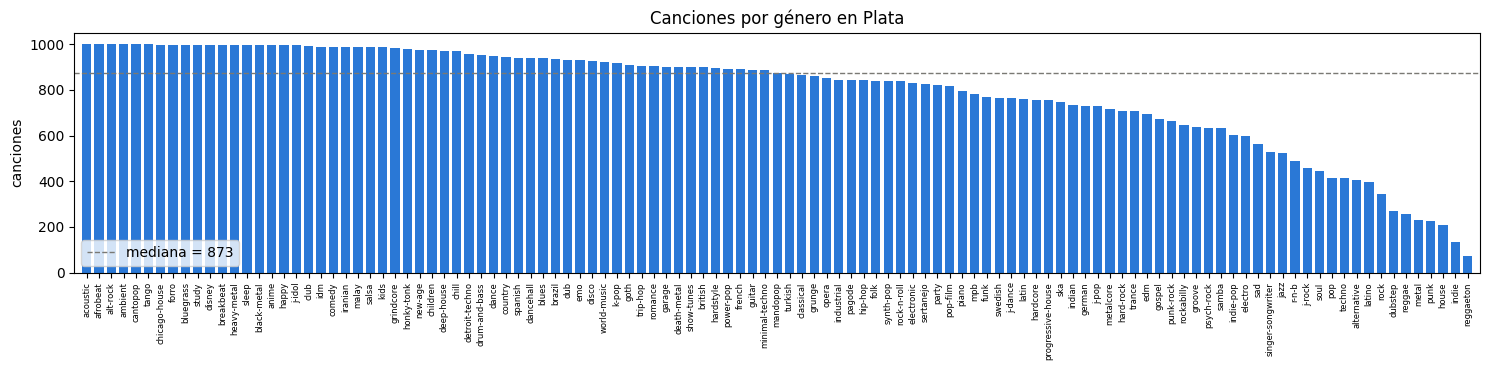

,0
géneros,113
canciones,89741
clase más chica,reggaeton (74)
clase más grande,acoustic (1000)
mediana por clase,873.0
peso de la clase más grande,0.0111
acertar al azar (1/113),0.0088


In [ ]:
conteo_generos = df["track_genre"].value_counts()

fig, ax = plt.subplots(figsize=(15, 3.8))
ax.bar(range(len(conteo_generos)), conteo_generos.values, color=AZUL, width=0.75)
ax.axhline(conteo_generos.median(), color=GRIS, ls="--", lw=1, label=f"mediana = {conteo_generos.median():.0f}")
ax.set_xticks(range(len(conteo_generos)))
ax.set_xticklabels(conteo_generos.index, rotation=90, fontsize=6)
ax.set_xlim(-1, len(conteo_generos))
ax.set_ylabel("canciones")
ax.set_title("Canciones por género en Plata")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

pd.Series({"géneros": conteo_generos.size,
           "canciones": int(conteo_generos.sum()),
           "clase más chica": f"{conteo_generos.idxmin()} ({conteo_generos.min()})",
           "clase más grande": f"{conteo_generos.idxmax()} ({conteo_generos.max()})",
           "mediana por clase": float(conteo_generos.median()),
           "peso de la clase más grande": round(conteo_generos.max() / conteo_generos.sum(), 4),
           "acertar al azar (1/113)": round(1 / conteo_generos.size, 4)})

**Lectura.** 113 géneros, con una mediana de 873 canciones por género y una cola chica (la más chica es `reggaeton`, con 74). El dataset está **casi balanceado**: el problema no es el desbalance sino la cantidad de clases. Un modelo que siempre contesta el género más grande acierta ~1 %: cualquier número se lee contra eso, no contra 100 %.

### 1.2 Las columnas que no pueden estar, y las etiquetas que no son una sola

- `track_genre`: **target**; nunca entra como columna. `track_id`: identificador.
- No se reutiliza el `df` del EDA: allí se crearon columnas derivadas del género (`is_electronic`), que serían **fuga**.
- `key`, `mode`, `time_signature` se tratan como **categóricas** para no imponer distancias entre categorías.
- `loudness` (H3, redundante con `energy`) y `time_signature` (H4, señal débil) son candidatas a salir; se decide por CV en la Parte 6, no por el EDA.

In [ ]:
NUMERICAS = ["duration_ms", "danceability", "energy", "loudness", "speechiness",
             "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
CATEGORICAS = ["key", "mode", "time_signature"]
FEATURES = NUMERICAS + CATEGORICAS
OBJETIVO = "track_genre"

faltantes = [c for c in ["track_id", OBJETIVO] + FEATURES if c not in df.columns]
assert not faltantes, f"Faltan columnas esperadas: {faltantes}"
assert not df[OBJETIVO].isna().any(), "Hay targets nulos"
assert not df["track_id"].duplicated().any(), "track_id duplicados"

X = df[FEATURES].copy()
y = df[OBJETIVO].copy()
assert OBJETIVO not in X.columns and "track_id" not in X.columns

display(X.isna().sum().to_frame("nulos").T)
pd.Series({"canciones": len(X), "columnas de entrada": X.shape[1],
           "ceros en tempo (se imputan adentro del pipeline)": int((X["tempo"] == 0).sum())})

,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,key,mode,time_signature
nulos,0,0,0,0,0,0,0,0,0,0,0,0,0


,0
canciones,89741
columnas de entrada,13
ceros en tempo (se imputan adentro del pipeline),157


Una cosa más antes de partir, que en la versión anterior se trató como precaución y conviene **medir**: hay filas con **exactamente el mismo audio** y distinto `track_id` (la misma grabación publicada en un single y en un álbum). Si esas copias tienen **géneros distintos**, la etiqueta no es una propiedad del sonido sino de dónde se publicó la canción, y ningún modelo de audio puede acertar las dos.

In [ ]:
# huella determinística calculada sólo con las columnas de entrada
huella_audio = pd.util.hash_pandas_object(X, index=False).to_numpy()

grupos_audio = (pd.DataFrame({"huella": huella_audio, "genero": y.to_numpy()})
                .groupby("huella")["genero"]
                .agg(copias="size", generos="nunique",
                     moda=lambda s: s.value_counts().iloc[0],
                     lista=lambda s: ", ".join(sorted(set(s)))))
repetidos = grupos_audio[grupos_audio["copias"] > 1]
en_conflicto = repetidos[repetidos["generos"] > 1]

display(pd.Series({"grupos de audio repetido": len(repetidos),
                   "filas en esos grupos": int(repetidos["copias"].sum()),
                   "grupos con más de un género": len(en_conflicto),
                   "filas en grupos con más de un género": int(en_conflicto["copias"].sum()),
                   "filas que ningún modelo de audio puede acertar": int((en_conflicto["copias"] - en_conflicto["moda"]).sum())}))

# qué pares de géneros comparten el mismo audio con más frecuencia
pares = (en_conflicto["lista"].str.split(", ")
         .apply(lambda g: list(combinations(g, 2))).explode()
         .value_counts().head(12).rename_axis("par de géneros").to_frame("grupos de audio idéntico"))
pares

,0
grupos de audio repetido,3022
filas en esos grupos,9284
grupos con más de un género,260
filas en grupos con más de un género,1020
filas que ningún modelo de audio puede acertar,305


,grupos de audio idéntico
par de géneros,
"(latin, latino)",21
"(alternative, grunge)",14
"(dance, edm)",14
"(dance, dancehall)",10
"(dub, dubstep)",9
"(latin, spanish)",7
"(hip-hop, latino)",6
"(edm, funk)",6
"(disco, synth-pop)",5


**Lectura.** De las 9.284 filas con audio repetido, **1.020** (260 grupos) tienen el mismo audio con **géneros distintos**: es error irreducible para cualquier modelo de audio. Los pares que más se repiten (✏️ mirar la tabla: típicamente `kids`–`children`, `latin`–`latino`, `mandopop`–`cantopop`) son los mismos que después aparecen en la matriz de confusión.

Y esto es sólo la punta. En la fuente original (Bronce, 114.000 filas) **16.299 de los 89.741 `track_id` (18 %) aparecían con más de un género**, y Plata se quedó con el primero. Para casi una de cada cinco canciones la etiqueta es una elección de deduplicación, no una propiedad del sonido. Es el argumento más fuerte para informar **top-k** (Parte 12) y no sólo el top-1.

### 1.3 La partición, antes de cualquier modelo

Se reserva ~20 % como test externo, que no participa de ninguna elección. Como hay audio repetido, las copias exactas se tratan como **un mismo grupo** (`StratifiedGroupKFold`): ninguna canción idéntica queda de los dos lados. En el resto se fijan **5 folds** que usan todos los experimentos del notebook, incluidos los de familias de la Parte 11.

In [ ]:
filas_repetidas = int(repetidos["copias"].sum())
USAR_GRUPOS = filas_repetidas > 0

if USAR_GRUPOS:
    separador_externo = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    idx_train, idx_test = next(separador_externo.split(X, y, groups=huella_audio))
    grupos_train = huella_audio[idx_train]
else:
    idx_train, idx_test = train_test_split(np.arange(len(X)), test_size=0.20, stratify=y, random_state=SEMILLA)
    grupos_train = None

X_train, X_test = X.iloc[idx_train].copy(), X.iloc[idx_test].copy()
y_train, y_test = y.iloc[idx_train].copy(), y.iloc[idx_test].copy()

if USAR_GRUPOS:
    cv_objeto = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEMILLA)
    CV_SPLITS = list(cv_objeto.split(X_train, y_train, groups=grupos_train))
else:
    cv_objeto = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEMILLA)
    CV_SPLITS = list(cv_objeto.split(X_train, y_train))

# auditoría: el mismo audio nunca cruza train/test
assert not set(huella_audio[idx_train]).intersection(huella_audio[idx_test])

display(pd.Series({"validación": type(cv_objeto).__name__,
                   "entrenamiento": len(X_train), "test": len(X_test),
                   "clases en train": y_train.nunique(), "clases en test": y_test.nunique()}))
pd.DataFrame([{"entrena con": len(a), "valida sobre": len(b)} for a, b in CV_SPLITS],
             index=[f"fold {i + 1}" for i in range(CV_FOLDS)])

,0
validación,StratifiedGroupKFold
entrenamiento,71701
test,18040
clases en train,113
clases en test,113


,entrena con,valida sobre
fold 1,57314,14387
fold 2,57352,14349
fold 3,57359,14342
fold 4,57415,14286
fold 5,57364,14337


In [ ]:
# la estratificación por grupos, ¿mantuvo las proporciones de cada género?
proporciones = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                             "test": y_test.value_counts(normalize=True)})
proporciones["diferencia"] = (proporciones["train"] - proporciones["test"]).abs()

display(pd.Series({"máxima diferencia de proporción": round(proporciones["diferencia"].max(), 4),
                   "proporción esperada por clase (1/113)": round(1 / 113, 4),
                   "clase más chica en test": f"{y_test.value_counts().idxmin()} ({y_test.value_counts().min()})"}))
proporciones.sort_values("diferencia", ascending=False).head(6).round(4)

,0
máxima diferencia de proporción,0.0029
proporción esperada por clase (1/113),0.0088
clase más chica en test,reggaeton (15)


,train,test,diferencia
track_genre,,,
blues,0.0099,0.0128,0.0029
alt-rock,0.0116,0.0091,0.0026
latin,0.0079,0.0105,0.0025
edm,0.0073,0.0096,0.0024
j-idol,0.0116,0.0092,0.0024
hip-hop,0.0089,0.0113,0.0023


### 1.4 El piso

Un `DummyClassifier` que contesta siempre la clase más frecuente, medido con los mismos folds. Es el número contra el que se lee todo lo que sigue.

In [ ]:
piso_cv = cross_validate(DummyClassifier(strategy="most_frequent"), X_train, y_train, cv=CV_SPLITS,
                         scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"})
f1_dummy = float(piso_cv["test_f1_macro"].mean())

pd.Series({"accuracy del piso (CV)": piso_cv["test_accuracy"].mean(),
           "F1 macro del piso (CV)": f1_dummy,
           "accuracy de acertar al azar (1/113)": 1 / 113}).round(4)

,0
accuracy del piso (CV),0.0104
F1 macro del piso (CV),0.0002
accuracy de acertar al azar (1/113),0.0088


## Parte 2 — Mirar las X antes del modelo: análisis cruzado

Todo lo de esta parte se calcula **sólo sobre el entrenamiento**: mirar el test para decidir algo, aunque sea qué graficar, ya es usarlo. Tres preguntas: cómo se distribuye cada columna, cuáles dicen lo mismo, y cuáles separan géneros.

### 2.1 Cada columna por separado

In [ ]:
X_train[NUMERICAS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
duration_ms,71701.0,229389.113,114708.118,0.000,172965.000,213533.000,264584.000,5237295.000
danceability,71701.0,0.562,0.176,0.000,0.450,0.576,0.692,0.985
energy,71701.0,0.635,0.257,0.000,0.457,0.677,0.854,1.000
loudness,71701.0,-8.482,5.215,-49.531,-10.312,-7.176,-5.095,4.532
speechiness,71701.0,0.087,0.113,0.000,0.036,0.049,0.086,0.965
acousticness,71701.0,0.329,0.338,0.000,0.017,0.189,0.624,0.996
instrumentalness,71701.0,0.173,0.324,0.000,0.000,0.000,0.098,1.000
liveness,71701.0,0.217,0.195,0.000,0.098,0.132,0.281,1.000
valence,71701.0,0.470,0.263,0.000,0.250,0.457,0.682,0.994
tempo,71701.0,122.069,30.134,0.000,99.198,122.012,140.088,220.525


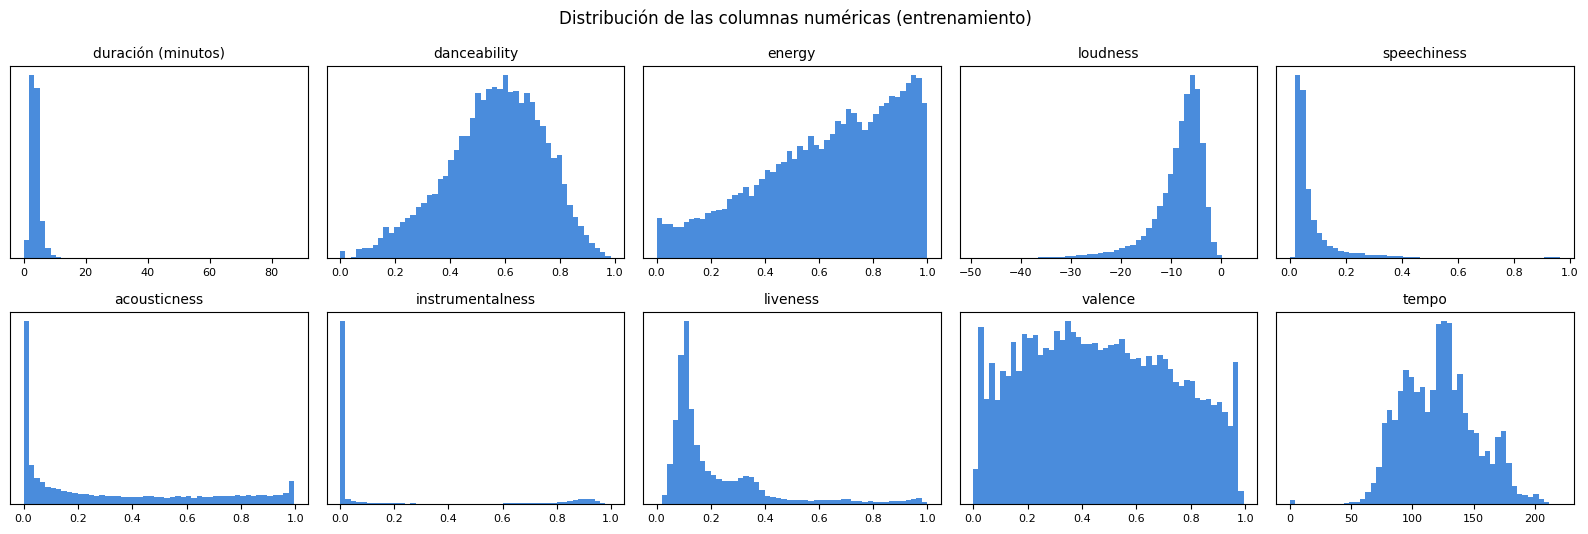

,"proporción en 0 o casi 0 (< 0,01)",asimetría
instrumentalness,0.683,1.564
speechiness,0.002,4.543
liveness,0.000,2.054
acousticness,0.213,0.652
duration_ms,0.000,11.782


In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5.4))
for ax, col in zip(axes.flat, NUMERICAS):
    valores = X_train[col]
    if col == "duration_ms":
        valores = valores / 60000
    ax.hist(valores, bins=50, color=AZUL, alpha=0.85)
    ax.set_title(col if col != "duration_ms" else "duración (minutos)", fontsize=10)
    ax.tick_params(labelsize=8)
    ax.set_yticks([])
fig.suptitle("Distribución de las columnas numéricas (entrenamiento)", fontsize=12)
plt.tight_layout()
plt.show()

pd.DataFrame({"proporción en 0 o casi 0 (< 0,01)": (X_train[NUMERICAS] < 0.01).mean(),
              "asimetría": X_train[NUMERICAS].skew()}).loc[["instrumentalness", "speechiness", "liveness", "acousticness", "duration_ms"]].round(3)

**Lectura.** ✏️ Verificar con la tabla: `instrumentalness`, `speechiness` y `liveness` están amontonadas cerca de 0 con colas largas; `duration_ms` es muy asimétrica. Para los árboles da igual (cortan por umbrales); para la logística y k vecinos, la escala estándar no corrige la asimetría, y es una de las razones de su desventaja.

### 2.2 Las columnas entre sí: redundancia

Correlación de Spearman (por rangos, robusta a las colas largas de `duration_ms` o `instrumentalness`). Dos columnas muy correlacionadas se reparten la importancia en la Parte 9 y son candidatas a la ablación de la Parte 6.

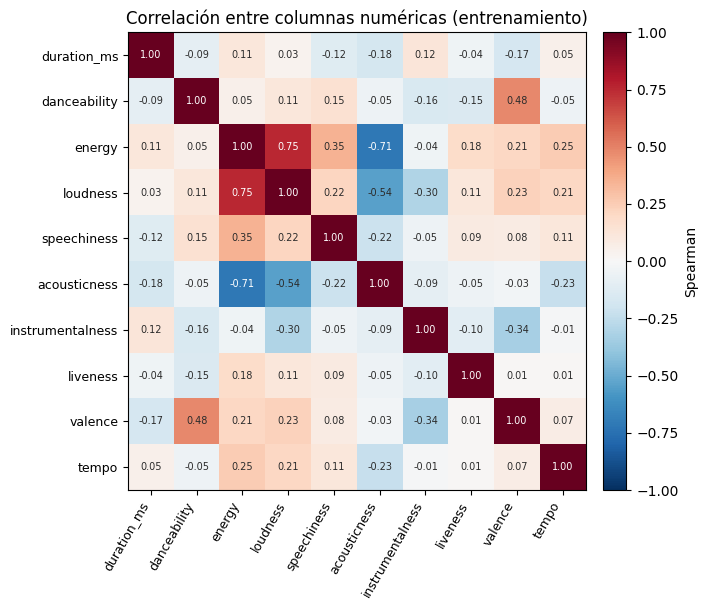

Spearman    |r|
energy           loudness         0.754  0.754
                 acousticness    -0.714  0.714
loudness         acousticness    -0.540  0.540
danceability     valence          0.478  0.478
energy           speechiness      0.350  0.350
instrumentalness valence         -0.336  0.336

In [ ]:
corr = X_train[NUMERICAS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERICAS)), NUMERICAS, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(NUMERICAS)), NUMERICAS, fontsize=9)
for i in range(len(NUMERICAS)):
    for j in range(len(NUMERICAS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "#2b2b2b")
fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03, label="Spearman")
ax.set_title("Correlación entre columnas numéricas (entrenamiento)")
plt.tight_layout()
plt.show()

# los pares más correlacionados, en tabla
pares_corr = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
              .rename("Spearman").to_frame())
pares_corr["|r|"] = pares_corr["Spearman"].abs()
pares_corr.sort_values("|r|", ascending=False).head(6).round(3)

**Lectura.** ✏️ El par más fuerte debería ser `energy`–`loudness` (H3 de la Entrega 2), seguido de `energy`–`acousticness` (negativo). Dos columnas que dicen casi lo mismo **se reparten la importancia** en la Parte 9: una importancia baja de `loudness` no probará que no sirve.

### 2.3 Las columnas contra el objetivo: cuánto separa cada una a los géneros

Para las numéricas, **η²**: la fracción de la varianza de la columna que se explica por el género (0 = todos los géneros tienen el mismo promedio, 1 = el género determina el valor). Para las categóricas, la **V de Cramér** de su tabla cruzada con el género. Es la misma medida de las hipótesis de la Entrega 2, ahora sobre el entrenamiento solo.

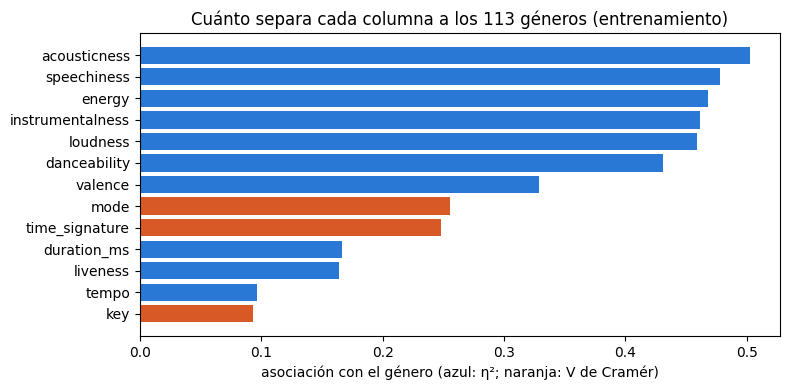

,medida,valor
acousticness,η²,0.502
speechiness,η²,0.478
energy,η²,0.468
instrumentalness,η²,0.462
loudness,η²,0.459
danceability,η²,0.431
valence,η²,0.329
mode,V de Cramér,0.255
time_signature,V de Cramér,0.248
duration_ms,η²,0.167


In [ ]:
def eta_cuadrado(columna, grupos):
    """Fracción de la varianza de la columna explicada por el grupo."""
    media = columna.mean()
    entre = columna.groupby(grupos).agg(lambda s: len(s) * (s.mean() - media) ** 2).sum()
    return entre / ((columna - media) ** 2).sum()

def v_de_cramer(columna, grupos):
    tabla = pd.crosstab(columna, grupos)
    chi2 = chi2_contingency(tabla)[0]
    return np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))

asociacion = pd.concat([
    pd.DataFrame({"medida": "η²", "valor": [eta_cuadrado(X_train[c], y_train) for c in NUMERICAS]}, index=NUMERICAS),
    pd.DataFrame({"medida": "V de Cramér", "valor": [v_de_cramer(X_train[c], y_train) for c in CATEGORICAS]}, index=CATEGORICAS),
]).sort_values("valor", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
mostradas = asociacion.iloc[::-1]
ax.barh(mostradas.index, mostradas["valor"], color=[AZUL if m == "η²" else NARANJA for m in mostradas["medida"]])
ax.set_xlabel("asociación con el género (azul: η²; naranja: V de Cramér)")
ax.set_title("Cuánto separa cada columna a los 113 géneros (entrenamiento)")
plt.tight_layout()
plt.show()
asociacion.round(3)

**Lectura.** ✏️ Ordenar con la tabla: las columnas de mayor η² son las que más separan géneros en promedio; las categóricas (`key`, `mode`, `time_signature`) quedan abajo, coherente con H4. Ojo: η² mide diferencias de **promedio** entre géneros; un modelo de árboles también aprovecha combinaciones y umbrales que η² no ve.

### 2.4 Los géneros cruzados con las columnas: el perfil de audio de cada género

El promedio de cada columna en cada género, estandarizado **entre géneros** (z = cuántos desvíos se aleja ese género del promedio de los 113). Filas ordenadas por similitud (un agrupamiento jerárquico, sólo para ordenar el dibujo) y columnas por η². Esta tabla de perfiles es la misma que en la Parte 10 se usa para agrupar géneros sin etiqueta.

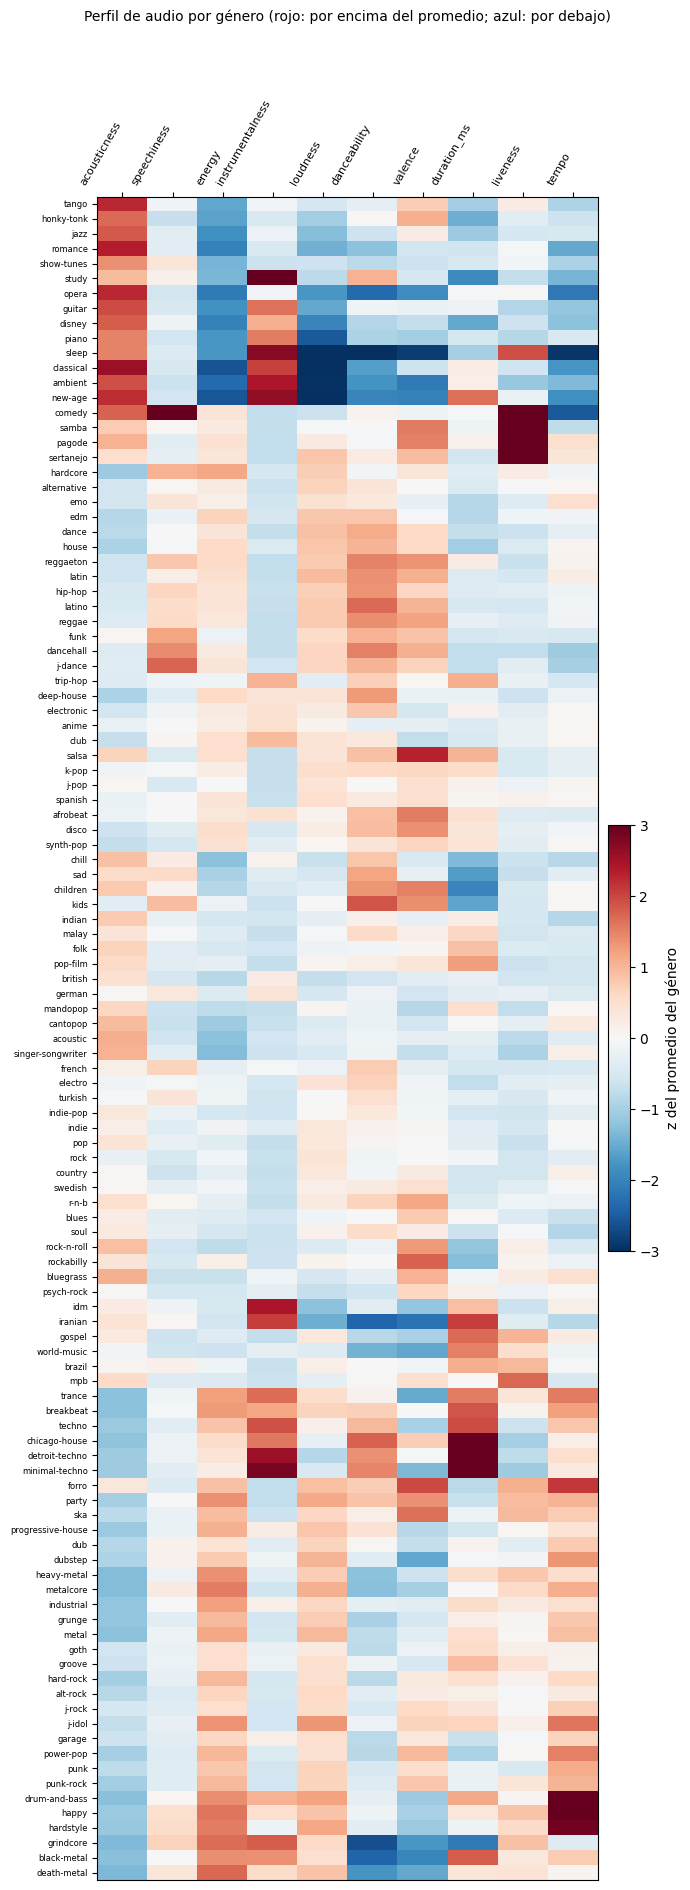

In [ ]:
# perfiles de entrenamiento: tempo = 0 se trata como faltante, igual que en el pipeline
perfiles_train = (X_train[NUMERICAS].assign(tempo=X_train["tempo"].replace(0, np.nan))
                  .groupby(y_train).mean())
perfiles_z = (perfiles_train - perfiles_train.mean()) / perfiles_train.std()

orden_generos = perfiles_z.index[leaves_list(linkage(perfiles_z, method="ward"))]
orden_columnas = [c for c in asociacion.index if c in NUMERICAS]

fig, ax = plt.subplots(figsize=(7, 19))
im = ax.imshow(perfiles_z.loc[orden_generos, orden_columnas], cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(orden_columnas)), orden_columnas, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(orden_generos)), orden_generos, fontsize=6)
ax.xaxis.set_ticks_position("top"); ax.xaxis.set_label_position("top")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="z del promedio del género")
ax.set_title("Perfil de audio por género (rojo: por encima del promedio; azul: por debajo)", fontsize=10, pad=55)
plt.tight_layout()
plt.show()

**Lectura.** El orden jerárquico arma bloques visibles (✏️ identificar: uno acústico/instrumental —`classical`, `piano`, `sleep`, `ambient`—, uno enérgico y fuerte —metal y electrónica dura—, y una franja ancha de pop/rock/latino con z cerca de 0). Esa franja ancha, donde las filas casi no se distinguen por color, es exactamente donde el modelo se va a equivocar.

### 2.5 El problema, dibujado: géneros distintos contra géneros parecidos

Las dos columnas de mayor η², para dos grupos de cinco géneros. A la izquierda, géneros que el EDA mostró lejanos; a la derecha, cinco subgéneros de la electrónica de pista.

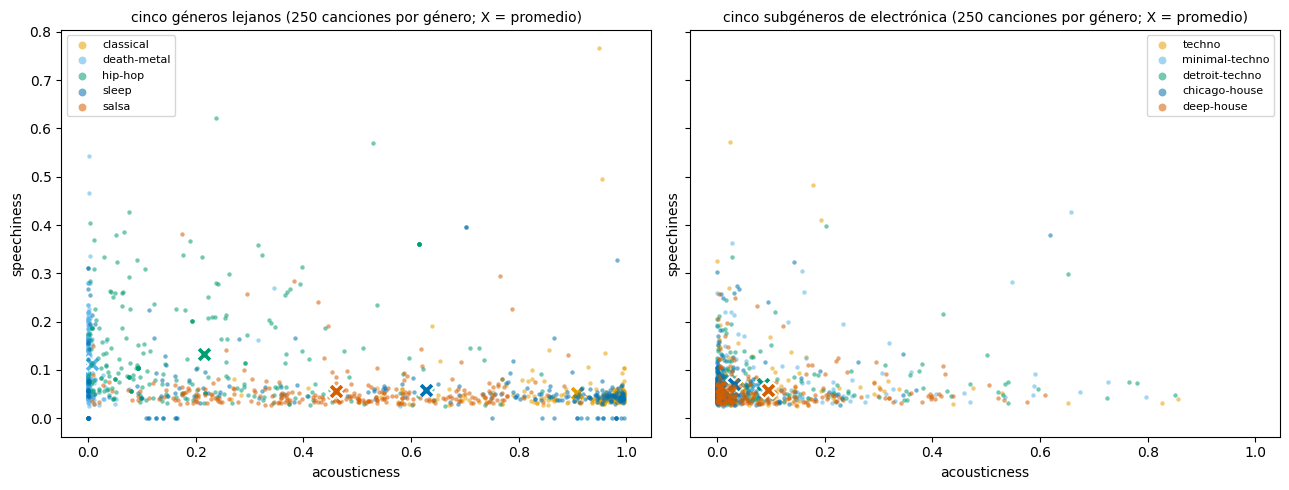

,acousticness,speechiness,energy,instrumentalness
desvío entre los promedios de,,,,
géneros lejanos,0.359,0.038,0.30,0.328
subgéneros de electrónica,0.024,0.007,0.04,0.203


In [ ]:
x_col, y_col = orden_columnas[0], orden_columnas[1]
DISTINTOS = ["classical", "death-metal", "hip-hop", "sleep", "salsa"]
PARECIDOS = ["techno", "minimal-techno", "detroit-techno", "chicago-house", "deep-house"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, grupo, titulo in [(axes[0], DISTINTOS, "cinco géneros lejanos"), (axes[1], PARECIDOS, "cinco subgéneros de electrónica")]:
    for color, genero in zip(OKABE_ITO, grupo):
        del_genero = X_train.loc[y_train == genero, [x_col, y_col]]
        puntos = del_genero.sample(min(250, len(del_genero)), random_state=SEMILLA)
        ax.scatter(puntos[x_col], puntos[y_col], s=10, alpha=0.55, color=color, label=genero, linewidths=0)
        ax.scatter(*puntos.mean(), s=140, marker="X", color=color, edgecolors="white", linewidths=1.5)
    ax.set_title(f"{titulo} (250 canciones por género; X = promedio)", fontsize=10)
    ax.set_xlabel(x_col); ax.set_ylabel(y_col)
    ax.legend(fontsize=8, markerscale=1.8)
plt.tight_layout()
plt.show()

# lo mismo en números: el desvío de cada grupo de géneros alrededor de su propio promedio
pd.DataFrame({"géneros lejanos": perfiles_train.loc[DISTINTOS, orden_columnas[:4]].std(),
              "subgéneros de electrónica": perfiles_train.loc[PARECIDOS, orden_columnas[:4]].std()}
             ).T.round(3).rename_axis("desvío entre los promedios de")

**Lectura.** A la izquierda las nubes tienen centros separados; a la derecha los cinco promedios caen casi en el mismo punto y las nubes se superponen por completo. La tabla lo dice en números: el desvío entre los promedios de los subgéneros es una fracción del de los géneros lejanos. **Ningún modelo separa con estas columnas lo que en estas columnas no está separado**: es el techo del problema, antes de entrenar nada.

## Parte 3 — El pipeline, con un transformador propio

La preparación es parte del modelo y se ajusta **sólo sobre el entrenamiento de cada fold**:

- Numéricas: imputación por mediana y `StandardScaler`.
- `tempo`: el 0 significa «sin tempo detectado»; se convierte en faltante con `SimpleImputer(missing_values=0)` **adentro** del pipeline.
- Categóricas: imputación por moda y `OneHotEncoder(handle_unknown="ignore")`.

Y un paso nuevo, con la receta de la sección 2.7 de la Práctica 1. La Práctica 2 (Parte 5) mostró que un modelo de árboles no puede **restar** dos columnas: para expresar «más acústica que enérgica» necesita una escalera de cortes. `ContrastesDeAudio` agrega las **21 restas** entre los siete descriptores que comparten escala 0–1 (`danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`). Las columnas de otra escala (`tempo`, `loudness`, `duration_ms`) quedan afuera: restar decibeles de pulsos por minuto no tiene sentido. Si sirve o no se mide en la Parte 6.

In [ ]:
ESCALA_01 = ["danceability", "energy", "speechiness", "acousticness", "instrumentalness", "liveness", "valence"]
PARES_01 = list(combinations(ESCALA_01, 2))
CONTRASTES = [f"{a}_menos_{b}" for a, b in PARES_01]


class ContrastesDeAudio(BaseEstimator, TransformerMixin):
    """Agrega una columna a_menos_b por cada par (a, b) de descriptores en escala 0-1."""

    def __init__(self, pares=()):
        self.pares = pares                       # se guarda tal cual: get_params lo lee de acá

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)   # lo aprendido, con guión bajo
        return self

    def transform(self, X):
        nuevas = pd.DataFrame({f"{a}_menos_{b}": X[a] - X[b] for a, b in self.pares}, index=X.index)
        return pd.concat([X, nuevas], axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.concatenate([self.feature_names_in_, [f"{a}_menos_{b}" for a, b in self.pares]])


# los dos verbos sobre tres canciones, mostrando tres de las 21 restas
ContrastesDeAudio(pares=PARES_01).fit(X_train).transform(X_train.head(3))[ESCALA_01[:3] + CONTRASTES[:3]].round(3)

,danceability,energy,speechiness,danceability_menos_energy,danceability_menos_speechiness,danceability_menos_acousticness
0,0.676,0.461,0.143,0.215,0.533,0.644
1,0.420,0.166,0.076,0.254,0.344,-0.504
2,0.438,0.359,0.056,0.079,0.382,0.228


In [ ]:
def construir_preparador(columnas):
    numericas = [c for c in columnas if c in NUMERICAS + CONTRASTES and c != "tempo"]
    categorias = [c for c in CATEGORICAS if c in columnas]
    transformaciones = []
    if numericas:
        transformaciones.append(("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                                        ("escalar", StandardScaler())]), numericas))
    if "tempo" in columnas:
        transformaciones.append(("tempo", Pipeline([("imputar_ceros", SimpleImputer(missing_values=0, strategy="median")),
                                                    ("escalar", StandardScaler())]), ["tempo"]))
    if categorias:
        transformaciones.append(("categoricas", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                                                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
                                 categorias))
    return ColumnTransformer(transformaciones, remainder="drop")


def construir_pipeline(nombre_modelo, columnas, contrastes=False):
    """El pipeline completo; con contrastes=True agrega el paso derivar adelante."""
    pasos, columnas_prep = [], list(columnas)
    if contrastes:
        pasos.append(("derivar", ContrastesDeAudio(pares=PARES_01)))
        columnas_prep += CONTRASTES
    pasos += [("preparar", construir_preparador(columnas_prep)),
              ("clasificador", clone(MODELOS[nombre_modelo]))]
    return Pipeline(pasos)


def evaluar_cv(modelo, columnas):
    return cross_validate(modelo, X_train[columnas], y_train, cv=CV_SPLITS,
                          scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
                          return_train_score=True, n_jobs=N_JOBS_CV, error_score="raise")


def resumir_cv(scores, etiqueta):
    return {"Experimento": etiqueta,
            "F1 macro CV": np.mean(scores["test_f1_macro"]),
            "Desvío F1": np.std(scores["test_f1_macro"], ddof=1),
            "F1 train": np.mean(scores["train_f1_macro"]),
            "Brecha train-CV": np.mean(scores["train_f1_macro"]) - np.mean(scores["test_f1_macro"]),
            "Accuracy CV": np.mean(scores["test_accuracy"]),
            "Tiempo fit (s)": np.mean(scores["fit_time"])}

## Parte 4 — Seis familias, con barra de error

Mismas columnas, mismos folds, misma métrica. Respecto de la versión anterior se agregan **k vecinos** (no aprende nada: compara contra las canciones guardadas) y **gradient boosting** (árboles chicos en secuencia), las dos familias que las prácticas comparan y que faltaban. El boosting se usa con *early stopping*: sin él, con 113 clases y tasa 0,1, diverge (lo probamos aparte: F1 0,09).

**Regla previa:** si una alternativa compleja no supera a la más simple por más que el desvío, se prefiere la simple. No se usa el test.

In [17]:
MODELOS = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": LogisticRegression(max_iter=1200, C=1.0),
    "k vecinos": KNeighborsClassifier(n_neighbors=25, weights="distance"),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=22, min_samples_leaf=2,
                                            n_jobs=N_JOBS_MODELO, random_state=SEMILLA),
    "Gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, early_stopping=True,
                                                        random_state=SEMILLA),
}
COMPLEJIDAD = {"Regresión logística": 1, "k vecinos": 2, "Árbol de decisión": 2, "Random Forest": 3, "Gradient boosting": 3}

resultados_modelos = []
for nombre in MODELOS:
    print("Evaluando:", nombre)
    resultados_modelos.append(resumir_cv(evaluar_cv(construir_pipeline(nombre, FEATURES), FEATURES), nombre))

comparacion = (pd.DataFrame(resultados_modelos).sort_values("F1 macro CV", ascending=False)
               .reset_index(drop=True))
comparacion.round(4)

Evaluando: Dummy
Evaluando: Regresión logística
Evaluando: k vecinos
Evaluando: Árbol de decisión
Evaluando: Random Forest
Evaluando: Gradient boosting


,Experimento,F1 macro CV,Desvío F1,F1 train,Brecha train-CV,Accuracy CV,Tiempo fit (s)
0,Random Forest,0.2200,0.0048,0.9868,0.7668,0.2738,31.8584
1,Gradient boosting,0.2128,0.0044,0.8809,0.6681,0.2507,254.4663
2,k vecinos,0.1652,0.0021,0.9957,0.8305,0.1992,0.1685
3,Regresión logística,0.1458,0.0031,0.1587,0.0129,0.1961,28.3759
4,Árbol de decisión,0.1411,0.0029,0.4280,0.2869,0.1668,3.0855
5,Dummy,0.0002,0.0000,0.0002,0.0000,0.0104,0.1580


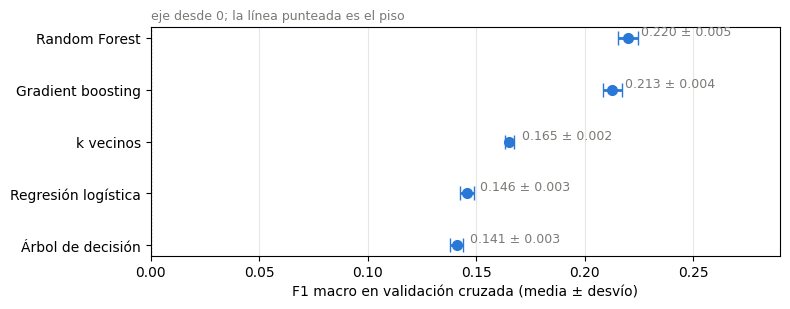

In [18]:
# la misma tabla, dibujada: el punto es la media y la barra, un desvío a cada lado
tabla_cv = comparacion[comparacion["Experimento"] != "Dummy"].set_index("Experimento").sort_values("F1 macro CV")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(tabla_cv["F1 macro CV"], tabla_cv.index, xerr=tabla_cv["Desvío F1"], fmt="o", color=AZUL,
            ecolor=AZUL, elinewidth=2, capsize=5, markersize=7)
for nombre, fila in tabla_cv.iterrows():
    ax.text(fila["F1 macro CV"] + 0.006, nombre, f"{fila['F1 macro CV']:.3f} ± {fila['Desvío F1']:.3f}",
            va="bottom", ha="left", fontsize=9, color=GRIS)
ax.axvline(f1_dummy, color=GRIS, ls=":", lw=1)
ax.set_xlabel("F1 macro en validación cruzada (media ± desvío)")
ax.set_xlim(0, tabla_cv["F1 macro CV"].max() + 0.07)
ax.set_title("eje desde 0; la línea punteada es el piso", fontsize=9, color=GRIS, loc="left")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura.** ✏️ En la versión anterior: Random Forest 0,220 ± 0,005, logística 0,146, árbol 0,141, piso 0,0002. Verificar dónde quedan k vecinos y gradient boosting. Si el bosque le gana a todos por más que varios desvíos, la elección no depende de la regla de parsimonia. La columna **Brecha** es la otra lectura: el bosque memoriza (F1 train ~0,99) y aun así generaliza mejor que el resto; la logística no memoriza nada y queda abajo porque el problema **no es lineal**, al revés que en las prácticas.

In [19]:
comp_reales = comparacion[comparacion["Experimento"] != "Dummy"].copy()
mejor = comp_reales.loc[comp_reales["F1 macro CV"].idxmax()]
comp_reales["Compite con el mejor"] = comp_reales.apply(
    lambda r: mejor["F1 macro CV"] - r["F1 macro CV"] <= max(mejor["Desvío F1"], r["Desvío F1"]), axis=1)
comp_reales["Orden complejidad"] = comp_reales["Experimento"].map(COMPLEJIDAD)

familia_elegida = (comp_reales[comp_reales["Compite con el mejor"]]
                   .sort_values(["Orden complejidad", "F1 macro CV"], ascending=[True, False])
                   .iloc[0]["Experimento"])
fila_elegida = comp_reales.set_index("Experimento").loc[familia_elegida]

display(pd.Series({"familia seleccionada": familia_elegida,
                   "ganancia frente al piso": round(fila_elegida["F1 macro CV"] - f1_dummy, 4),
                   "desvío de referencia": round(fila_elegida["Desvío F1"], 4)}))
comp_reales.round(4)

,0
familia seleccionada,Random Forest
ganancia frente al piso,0.2198
desvío de referencia,0.0048


,Experimento,F1 macro CV,Desvío F1,F1 train,Brecha train-CV,Accuracy CV,Tiempo fit (s),Compite con el mejor,Orden complejidad
0,Random Forest,0.2200,0.0048,0.9868,0.7668,0.2738,31.8584,True,3
1,Gradient boosting,0.2128,0.0044,0.8809,0.6681,0.2507,254.4663,False,3
2,k vecinos,0.1652,0.0021,0.9957,0.8305,0.1992,0.1685,False,2
3,Regresión logística,0.1458,0.0031,0.1587,0.0129,0.1961,28.3759,False,1
4,Árbol de decisión,0.1411,0.0029,0.4280,0.2869,0.1668,3.0855,False,2


## Parte 5 — Complejidad: la curva de validación

La brecha de la tabla anterior es enorme para los modelos de árboles: el Random Forest acierta casi todo lo que vio y una de cada cinco canciones que no vio. La curva de la teórica lo muestra con un solo hiperparámetro: la profundidad del árbol de decisión (el más barato de entrenar; el bosque promedia árboles de este tipo).

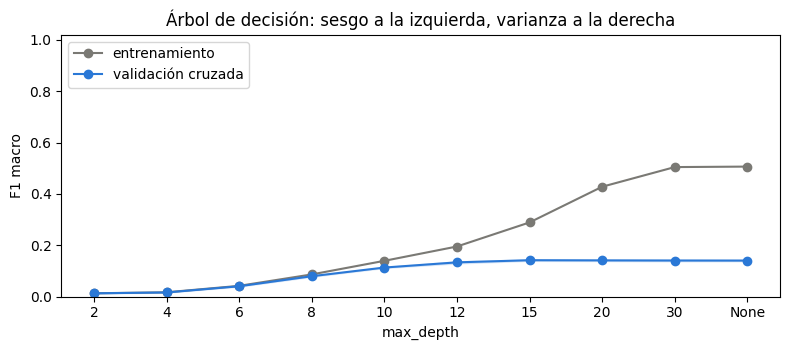

,2,4,6,8,10,12,15,20,30,None
train,0.013,0.017,0.042,0.086,0.139,0.195,0.289,0.428,0.505,0.507
cv,0.013,0.016,0.040,0.079,0.113,0.133,0.142,0.141,0.141,0.140
desvío cv,0.000,0.000,0.001,0.002,0.002,0.004,0.003,0.003,0.003,0.003


In [20]:
profundidades = [2, 4, 6, 8, 10, 12, 15, 20, 30, None]
tr, va = validation_curve(construir_pipeline("Árbol de decisión", FEATURES), X_train[FEATURES], y_train,
                          param_name="clasificador__max_depth", param_range=profundidades,
                          cv=CV_SPLITS, scoring="f1_macro", n_jobs=N_JOBS_CV)
etiquetas = [str(p) for p in profundidades]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(etiquetas, tr.mean(axis=1), marker="o", color=GRIS, label="entrenamiento")
ax.plot(etiquetas, va.mean(axis=1), marker="o", color=AZUL, label="validación cruzada")
ax.fill_between(etiquetas, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), color=AZUL, alpha=0.15)
ax.set_xlabel("max_depth"); ax.set_ylabel("F1 macro"); ax.set_ylim(0, 1.02)
ax.set_title("Árbol de decisión: sesgo a la izquierda, varianza a la derecha")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

curva_arbol = pd.DataFrame({"train": tr.mean(axis=1), "cv": va.mean(axis=1), "desvío cv": va.std(axis=1)}, index=etiquetas)
curva_arbol.T.round(3)

**Lectura.** ✏️ Las dos curvas van juntas hasta cierta profundidad (sesgo) y después train sube hacia 1 mientras CV se aplana o cae (varianza). Marcar la profundidad óptima y su F1: queda lejos del bosque, porque **limitar el árbol arregla la memorización, no el techo**; promediar árboles (el bosque) sí sube el techo.

## Parte 6 — Columnas: ablación y contrastes

Una **ablación** compara el mismo modelo con y sin ciertas columnas, sobre los mismos folds:
todas; sin `loudness` (H3); sin `time_signature` (H4); sin ambas. Se prefiere la representación más chica cuando la diferencia con la mejor es comparable al desvío.

In [21]:
VARIANTES = {
    "Todas": FEATURES.copy(),
    "Sin loudness": [c for c in FEATURES if c != "loudness"],
    "Sin time_signature": [c for c in FEATURES if c != "time_signature"],
    "Sin ambas": [c for c in FEATURES if c not in ("loudness", "time_signature")],
}

resultados_ab = []
for nombre, columnas in VARIANTES.items():
    print("Probando:", nombre)
    fila = resumir_cv(evaluar_cv(construir_pipeline(familia_elegida, columnas), columnas), nombre)
    fila["N° features originales"] = len(columnas)
    resultados_ab.append(fila)

tabla_ablacion = pd.DataFrame(resultados_ab).sort_values("F1 macro CV", ascending=False).reset_index(drop=True)
mejor_ab = tabla_ablacion.iloc[0]
tabla_ablacion["Compite con el mejor"] = tabla_ablacion.apply(
    lambda r: mejor_ab["F1 macro CV"] - r["F1 macro CV"] <= max(mejor_ab["Desvío F1"], r["Desvío F1"]), axis=1)
variante_elegida = (tabla_ablacion[tabla_ablacion["Compite con el mejor"]]
                    .sort_values(["N° features originales", "F1 macro CV"], ascending=[True, False])
                    .iloc[0]["Experimento"])
FEATURES_ELEGIDAS = VARIANTES[variante_elegida].copy()

display(tabla_ablacion.round(4))
pd.Series({"representación elegida": variante_elegida, "features": ", ".join(FEATURES_ELEGIDAS)})

Probando: Todas
Probando: Sin loudness
Probando: Sin time_signature
Probando: Sin ambas


,Experimento,F1 macro CV,Desvío F1,F1 train,Brecha train-CV,Accuracy CV,Tiempo fit (s),N° features originales,Compite con el mejor
0,Todas,0.2200,0.0048,0.9868,0.7668,0.2738,30.9396,13,True
1,Sin time_signature,0.2182,0.0038,0.9883,0.7701,0.2720,30.7577,12,True
2,Sin loudness,0.2123,0.0039,0.9843,0.7720,0.2647,28.7652,12,False
3,Sin ambas,0.2083,0.0044,0.9873,0.7790,0.2602,27.6744,11,False


,0
representación elegida,Sin time_signature
features,"duration_ms, danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo, key, mode"


Ahora el transformador de la Parte 3, sobre la representación elegida: **con y sin las 21 restas**. La misma regla: el paso se queda sólo si gana por más que el desvío, porque agrega columnas y tiempo.

In [22]:
res_sin = tabla_ablacion.set_index("Experimento").loc[variante_elegida]
scores_con = evaluar_cv(construir_pipeline(familia_elegida, FEATURES_ELEGIDAS, contrastes=True), FEATURES_ELEGIDAS)
res_con = pd.Series(resumir_cv(scores_con, f"{variante_elegida} + 21 contrastes")).drop("Experimento")

tabla_contrastes = pd.DataFrame({variante_elegida: res_sin[res_con.index], f"{variante_elegida} + 21 contrastes": res_con}).T
ganancia_contrastes = float(res_con["F1 macro CV"] - res_sin["F1 macro CV"])
USAR_CONTRASTES = ganancia_contrastes > max(float(res_con["Desvío F1"]), float(res_sin["Desvío F1"]))

display(tabla_contrastes.astype(float).round(4))
pd.Series({"ganancia de F1 macro": round(ganancia_contrastes, 4), "¿se usan los contrastes?": USAR_CONTRASTES})

,F1 macro CV,Desvío F1,F1 train,Brecha train-CV,Accuracy CV,Tiempo fit (s)
Sin time_signature,0.2182,0.0038,0.9883,0.7701,0.2720,30.7577
Sin time_signature + 21 contrastes,0.2020,0.0042,0.9887,0.7867,0.2503,68.7462


,0
ganancia de F1 macro,-0.0162
¿se usan los contrastes?,False


**Lectura.** ✏️ En la versión anterior se eligió *Sin time_signature* (0,218 vs 0,220, dentro del desvío, una columna menos). Para los contrastes: si ganan por más que el desvío, quedan en el pipeline y la grilla los usa; si no, **también es un resultado**: el bosque ya arma esas combinaciones con varios cortes, como el boosting de la Práctica 2, y se escribe así.

## Parte 7 — Ajuste de hiperparámetros y desbalance

Antes de la grilla, el desbalance medido: cuánto peso le daría `class_weight="balanced"` a cada clase. Si los pesos son cercanos a 1, balancear no puede cambiar mucho, y eso se dice antes de ver el resultado.

In [23]:
pesos = pd.Series(compute_class_weight("balanced", classes=np.sort(y_train.unique()), y=y_train),
                  index=np.sort(y_train.unique()), name="peso")
display(pd.Series({"canciones por clase en train (mín · mediana · máx)":
                       f"{y_train.value_counts().min()} · {y_train.value_counts().median():.0f} · {y_train.value_counts().max()}",
                   "clases con peso > 1,5": int((pesos > 1.5).sum()),
                   "peso máximo": round(pesos.max(), 2), "peso mínimo": round(pesos.min(), 2)}))
pesos.sort_values(ascending=False).head(8).round(2).to_frame()

,0
canciones por clase en train (mín · mediana · máx),59 · 696 · 835
"clases con peso > 1,5",17
peso máximo,10.75
peso mínimo,0.76


,peso
reggaeton,10.75
indie,6.41
punk,3.69
house,3.69
metal,3.39
reggae,3.02
dubstep,2.83
rock,2.39


El ajuste se hace **sólo** para la familia seleccionada, con `GridSearchCV` sobre los mismos 5 folds y el pipeline entero (incluido el paso de contrastes si quedó). Se registran **todas** las combinaciones. Con 113 clases y ninguna prioritaria **no se ajusta un umbral por clase** (la palanca de la sección 6.3 de la Práctica 2 es para una clase de interés).

In [24]:
GRILLAS = {
    "Regresión logística": {"clasificador__C": [0.1, 1.0, 10.0], "clasificador__class_weight": [None, "balanced"]},
    "k vecinos": {"clasificador__n_neighbors": [15, 50], "clasificador__weights": ["uniform", "distance"]},
    "Árbol de decisión": {"clasificador__max_depth": [12, 20, None], "clasificador__min_samples_leaf": [2, 8],
                          "clasificador__class_weight": [None, "balanced"]},
    "Random Forest": {"clasificador__n_estimators": [100], "clasificador__max_depth": [16, None],
                      "clasificador__min_samples_leaf": [2, 6], "clasificador__class_weight": [None, "balanced_subsample"]},
    "Gradient boosting": {"clasificador__learning_rate": [0.03, 0.05], "clasificador__max_leaf_nodes": [15, 31]},
}

pipeline_elegido = construir_pipeline(familia_elegida, FEATURES_ELEGIDAS, contrastes=USAR_CONTRASTES)
busqueda = GridSearchCV(pipeline_elegido, GRILLAS[familia_elegida], cv=CV_SPLITS,
                        scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"}, refit="f1_macro",
                        return_train_score=True, n_jobs=1, pre_dispatch=1, verbose=1, error_score="raise")
busqueda.fit(X_train[FEATURES_ELEGIDAS], y_train)

pd.Series({"mejores parámetros": {k.split("__")[-1]: v for k, v in busqueda.best_params_.items()},
           "mejor F1 macro CV": round(busqueda.best_score_, 4)})

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,0
mejores parámetros,"{'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}"
mejor F1 macro CV,0.2245


In [25]:
cv_resultados = pd.DataFrame(busqueda.cv_results_)
cols_grid = ([c for c in cv_resultados.columns if c.startswith("param_")] +
             ["mean_test_f1_macro", "std_test_f1_macro", "mean_train_f1_macro", "mean_test_accuracy",
              "mean_fit_time", "rank_test_f1_macro"])
tabla_grilla = (cv_resultados[cols_grid].sort_values("rank_test_f1_macro").reset_index(drop=True)
                .rename(columns=lambda c: c.replace("param_clasificador__", "")))
print("TODAS las combinaciones de la grilla:")
display(tabla_grilla.round(4))

if "param_clasificador__class_weight" in cv_resultados:
    tabla_pesos = (cv_resultados.assign(peso=cv_resultados["param_clasificador__class_weight"].astype(str))
                   .groupby("peso")
                   .agg(mejor_F1_macro=("mean_test_f1_macro", "max"), promedio_F1_macro=("mean_test_f1_macro", "mean"),
                        mejor_accuracy=("mean_test_accuracy", "max")))
    print("Pesos por clase (cada fila resume las combinaciones con ese peso):")
    display(tabla_pesos.round(4))

TODAS las combinaciones de la grilla:


,class_weight,max_depth,min_samples_leaf,n_estimators,mean_test_f1_macro,std_test_f1_macro,mean_train_f1_macro,mean_test_accuracy,mean_fit_time,rank_test_f1_macro
0,balanced_subsample,None,2,100,0.2245,0.0046,0.9928,0.2717,33.6196,1
1,None,None,2,100,0.2205,0.0040,0.9925,0.2726,33.2182,2
2,balanced_subsample,None,6,100,0.2133,0.0017,0.8781,0.2629,25.2616,3
3,None,None,6,100,0.2067,0.0030,0.8584,0.2657,24.6749,4
4,balanced_subsample,16,2,100,0.2059,0.0017,0.8364,0.2568,24.0508,5
5,None,16,2,100,0.2002,0.0030,0.8196,0.2602,23.5338,6
6,balanced_subsample,16,6,100,0.1990,0.0035,0.6703,0.2499,21.2343,7
7,None,16,6,100,0.1919,0.0024,0.6357,0.2556,20.3272,8


Pesos por clase (cada fila resume las combinaciones con ese peso):


,mejor_F1_macro,promedio_F1_macro,mejor_accuracy
peso,,,
None,0.2205,0.2048,0.2726
balanced_subsample,0.2245,0.2107,0.2717


**Lectura.** ✏️ Comparar el mejor contra el resto de la tabla: si varias filas están a menos de un desvío, la grilla es casi un empate y lo que importa es que ninguna configuración estaba mal. Sobre `class_weight`: con pesos entre ~0,9 y ~1,5 (casi todo balanceado), balancear sólo puede mover el F1 macro a través de las clases chicas; reportar cuánto.

## Parte 8 — El test, una vez

`GridSearchCV` reentrenó el mejor pipeline con todo el entrenamiento. Desde acá quedan **congelados** familia, columnas, contrastes, pesos e hiperparámetros. La siguiente es la **única** medición del test del modelo de géneros; si después de mirarla se cambia algo, deja de ser un test.

In [26]:
modelo_final = busqueda.best_estimator_
X_test_final = X_test[FEATURES_ELEGIDAS]

pd.Series({"modelo": familia_elegida, "representación": variante_elegida,
           "contrastes": USAR_CONTRASTES, "features": ", ".join(FEATURES_ELEGIDAS),
           "hiperparámetros": {k.split("__")[-1]: v for k, v in busqueda.best_params_.items()},
           "F1 macro CV": round(busqueda.best_score_, 4), "piso CV": round(f1_dummy, 4)})

,0
modelo,Random Forest
representación,Sin time_signature
contrastes,False
features,"duration_ms, danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo, key, mode"
hiperparámetros,"{'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}"
F1 macro CV,0.2245
piso CV,0.0002


In [27]:
# ÚNICA medición del test del modelo de 113 géneros
proba_test_genero = pd.DataFrame(modelo_final.predict_proba(X_test_final), columns=modelo_final.classes_, index=X_test.index)
y_pred = proba_test_genero.idxmax(axis=1).to_numpy()

f1_test = f1_score(y_test, y_pred, average="macro", zero_division=0)
accuracy_test = accuracy_score(y_test, y_pred)
top_test = {k: top_k_accuracy_score(y_test, proba_test_genero.values, k=k, labels=modelo_final.classes_) for k in (1, 3, 5)}

resumen_test = pd.DataFrame([{"Modelo": familia_elegida, "F1 macro CV": busqueda.best_score_, "F1 macro test": f1_test,
                              "Accuracy (top-1) test": accuracy_test, "Top-3 test": top_test[3], "Top-5 test": top_test[5],
                              "N test": len(y_test)}])
resumen_test.round(4)

,Modelo,F1 macro CV,F1 macro test,Accuracy (top-1) test,Top-3 test,Top-5 test,N test
0,Random Forest,0.2245,0.2407,0.2815,0.454,0.541,18040


In [28]:
reporte_clases = (pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T
                  .loc[sorted(y.unique())].sort_values("f1-score"))
reporte_clases["support"] = reporte_clases["support"].astype(int)

print("Los 12 géneros con peor F1 y los 12 con mejor (el reporte completo queda en reporte_clases):")
pd.concat({"peores": reporte_clases.head(12).reset_index(names="género"),
           "mejores": reporte_clases.tail(12).iloc[::-1].reset_index(names="género")}, axis=1).round(3)

Los 12 géneros con peor F1 y los 12 con mejor (el reporte completo queda en reporte_clases):


peores                                          mejores                                  
               género precision recall f1-score support         género precision recall f1-score support
0               indie     0.000  0.000    0.000      35         comedy     0.889  0.773    0.827     207
1              groove     0.125  0.014    0.026     138          sleep     0.763  0.827    0.793     202
2                punk     0.167  0.019    0.033      54      grindcore     0.588  0.792    0.675     216
3   singer-songwriter     0.045  0.038    0.041     105          study     0.511  0.851    0.638     194
4               blues     0.118  0.026    0.043     231  drum-and-bass     0.551  0.635    0.590     170
5                 mpb     0.074  0.045    0.056     154      classical     0.573  0.463    0.512     177
6                goth     0.093  0.045    0.061     176      hardstyle     0.439  0.606    0.509     165
7              j-rock     0.098  0.045    0.062      88         pagode     0.375  0.642    0.474     162
8              brazil     0.123  0.042    0.063     190          salsa     0.364  0.640    0.464     203
9             turkish     0.064  0.069    0.067     173          happy     0.423  0.498    0.457     203
10            swedish     0.103  0.052    0.069     154    black-metal     0.380  0.543    0.447     199
11         electronic     0.184  0.043    0.069     164        new-age     0.371  0.556    0.445     189

**Lectura.** ✏️ F1 macro test debe parecerse al de CV (en la versión anterior 0,241 vs 0,226): si coinciden, la búsqueda fue honesta. El dato nuevo es el **top-3/top-5**: cuántas veces el género correcto estaba entre las primeras respuestas aunque no fuera la primera. Los peores géneros por F1 (✏️ tabla) son subgéneros o etiquetas no sonoras (`indie`, `alternative`, `rock`…); los mejores, géneros con firma acústica extrema (`comedy`, `sleep`, `grindcore`…).

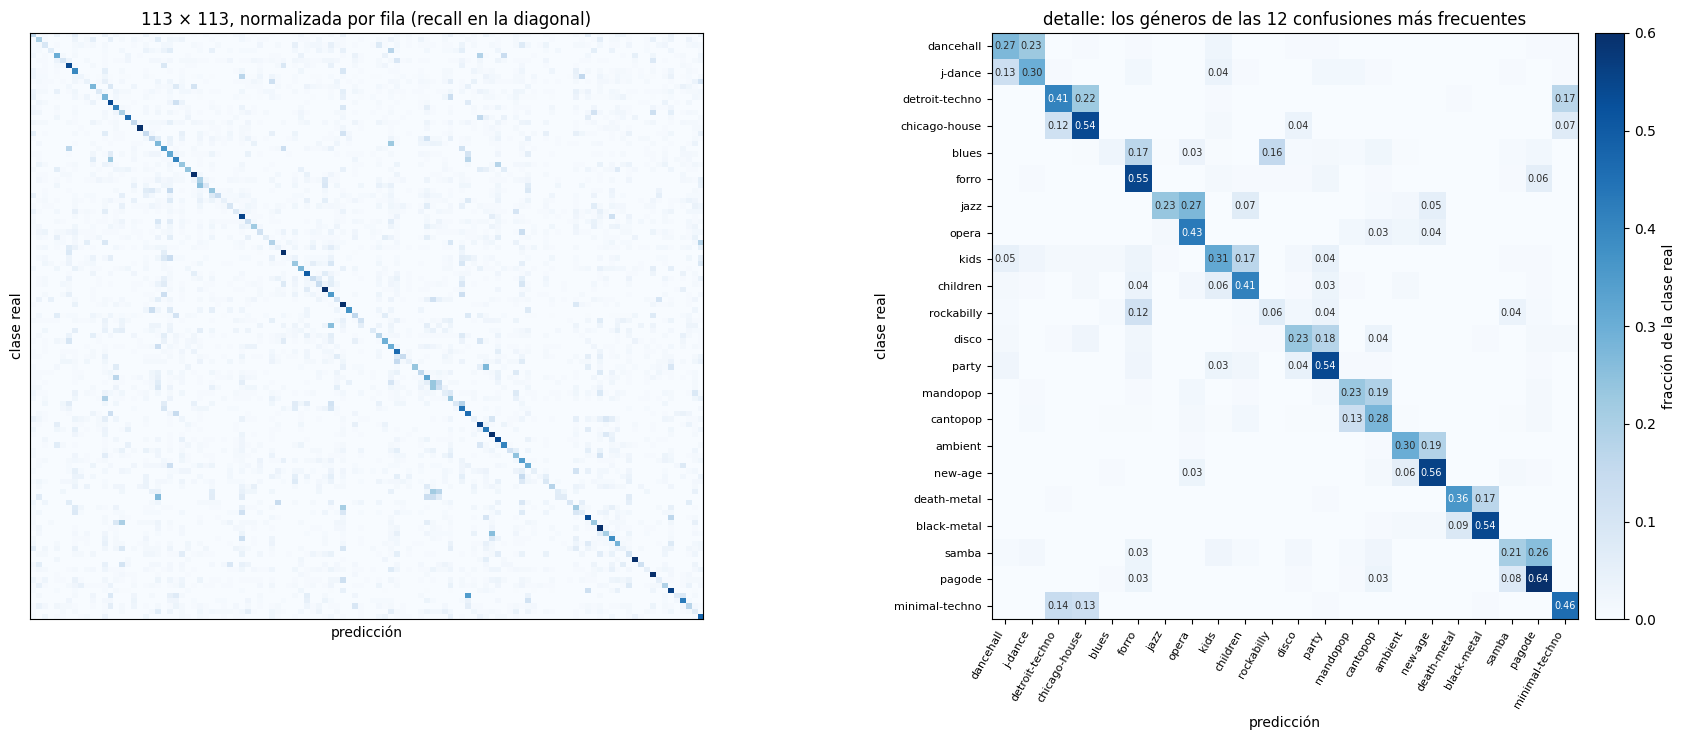

15 confusiones concretas más frecuentes:


,Género real,Predicho como,Errores,Total real,% de la clase real
0,dancehall,j-dance,43,190,22.63
1,detroit-techno,chicago-house,42,187,22.46
2,blues,forro,39,231,16.88
3,jazz,opera,36,132,27.27
4,kids,children,36,213,16.90
5,blues,rockabilly,36,231,15.58
6,disco,party,35,196,17.86
7,mandopop,cantopop,34,177,19.21
8,ambient,new-age,34,182,18.68
9,death-metal,black-metal,34,200,17.00


In [29]:
labels = np.array(sorted(y.unique()))
matriz_conteos = confusion_matrix(y_test, y_pred, labels=labels)
matriz_filas = confusion_matrix(y_test, y_pred, labels=labels, normalize="true")

# tabla auditable de confusiones concretas
confusiones = []
for i, real in enumerate(labels):
    total = int(matriz_conteos[i].sum())
    for j, predicho in enumerate(labels):
        if i != j and matriz_conteos[i, j] > 0:
            confusiones.append({"Género real": real, "Predicho como": predicho, "Errores": int(matriz_conteos[i, j]),
                                "Total real": total, "% de la clase real": 100 * matriz_conteos[i, j] / total})
tabla_errores = pd.DataFrame(confusiones).sort_values(["Errores", "% de la clase real"], ascending=False).reset_index(drop=True)

# una matriz de 113 × 113 no se lee: se muestra la submatriz de los géneros de las 12 confusiones más frecuentes
involucrados = list(dict.fromkeys(tabla_errores.head(12)[["Género real", "Predicho como"]].to_numpy().ravel()))
idx = [list(labels).index(g) for g in involucrados]
sub = matriz_filas[np.ix_(idx, idx)]

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].imshow(matriz_filas, cmap="Blues", vmin=0, vmax=0.6, aspect="auto")
axes[0].set_title("113 × 113, normalizada por fila (recall en la diagonal)")
axes[0].set_xlabel("predicción"); axes[0].set_ylabel("clase real"); axes[0].set_xticks([]); axes[0].set_yticks([])
im = axes[1].imshow(sub, cmap="Blues", vmin=0, vmax=0.6)
axes[1].set_xticks(range(len(involucrados)), involucrados, rotation=60, ha="right", fontsize=8)
axes[1].set_yticks(range(len(involucrados)), involucrados, fontsize=8)
for i in range(len(involucrados)):
    for j in range(len(involucrados)):
        if sub[i, j] >= 0.03:
            axes[1].text(j, i, f"{sub[i, j]:.2f}", ha="center", va="center", fontsize=7,
                         color="white" if sub[i, j] > 0.35 else "#2b2b2b")
axes[1].set_title("detalle: los géneros de las 12 confusiones más frecuentes")
axes[1].set_xlabel("predicción"); axes[1].set_ylabel("clase real")
fig.colorbar(im, ax=axes[1], fraction=0.04, pad=0.02, label="fracción de la clase real")
plt.tight_layout()
plt.show()

print("15 confusiones concretas más frecuentes:")
tabla_errores.head(15).round(2)

**Lectura.** La submatriz se lee sola: las confusiones grandes son **dentro de bloques** (electrónica de pista entre sí, `kids`/`children`, `cantopop`/`mandopop`, `latin`/`latino`) y varias coinciden con los pares de audio idéntico de la sección 1.2. Son errores de una etiqueta que el audio no puede resolver, no de un modelo mal ajustado. ✏️ Citar al menos una confusión concreta con sus números de la tabla.

## Parte 9 — En qué se apoya el modelo

Dos medidas que contestan preguntas distintas (Práctica 1, Parte 5):

- **Importancia por impureza** (`feature_importances_`): cuánto reduce la mezcla de géneros cada columna en los árboles. Se calcula sobre el entrenamiento, no tiene signo y favorece columnas con muchos valores distintos. Las columnas one-hot de `key` y `mode`, y las restas, se suman a su columna de origen para poder comparar.
- **Importancia por permutación** sobre el test con F1 macro: cuánto cae la métrica si una columna original se vuelve ruido. Permutar `energy` también arruina sus restas, así que mide el aporte **total** de la columna.

Se calcula después del resultado final, sólo para explicar: **no** se vuelve a seleccionar columnas con esto.

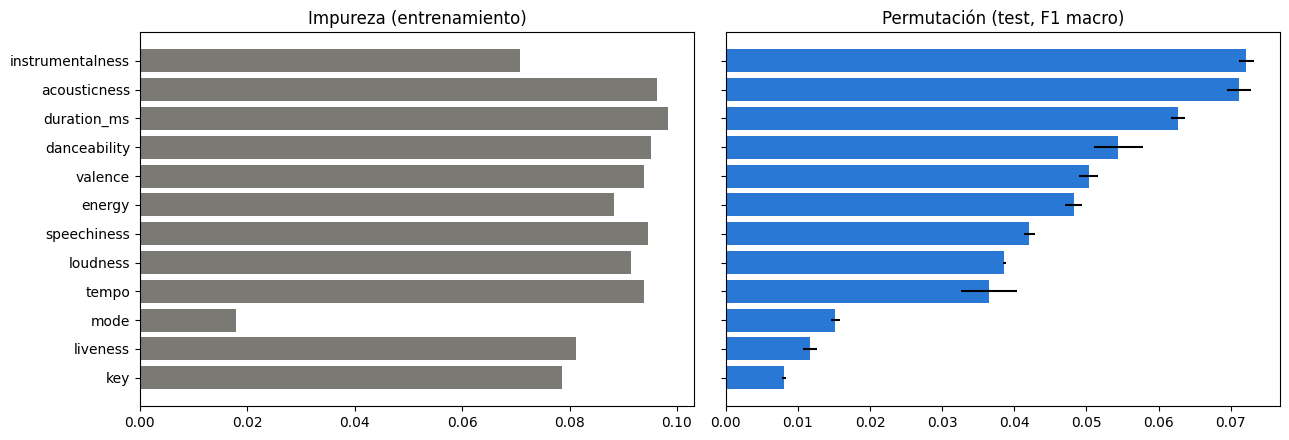

,"Impureza (train, suma 1)",Caída F1 macro al permutar (test),Desvío permutaciones,Ranking impureza,Ranking permutación
instrumentalness,0.0707,0.0722,0.0010,11,1
acousticness,0.0963,0.0712,0.0016,2,2
duration_ms,0.0983,0.0627,0.0010,1,3
danceability,0.0951,0.0544,0.0034,3,4
valence,0.0939,0.0503,0.0013,6,5
energy,0.0883,0.0483,0.0012,8,6
speechiness,0.0946,0.0420,0.0008,4,7
loudness,0.0914,0.0386,0.0002,7,8
tempo,0.0939,0.0365,0.0039,5,9
mode,0.0178,0.0152,0.0006,12,10


In [30]:
nombres = [n.split("__", 1)[1] for n in modelo_final.named_steps["preparar"].get_feature_names_out()]

def columna_de_origen(nombre):
    for cat in CATEGORICAS:
        if nombre.startswith(cat + "_"):
            return cat
    return nombre

impureza = pd.Series(modelo_final[-1].feature_importances_, index=nombres)
impureza_origen = impureza.groupby(impureza.index.map(columna_de_origen)).sum()
if USAR_CONTRASTES:
    # cada resta a_menos_b reparte su importancia por mitades entre a y b
    for a, b in PARES_01:
        valor = impureza_origen.pop(f"{a}_menos_{b}")
        impureza_origen[a] += valor / 2
        impureza_origen[b] += valor / 2

permutacion = permutation_importance(modelo_final, X_test_final, y_test, scoring="f1_macro",
                                     n_repeats=3, random_state=SEMILLA, n_jobs=1)

tabla_importancia = pd.DataFrame({"Impureza (train, suma 1)": impureza_origen,
                                  "Caída F1 macro al permutar (test)": pd.Series(permutacion.importances_mean, index=FEATURES_ELEGIDAS),
                                  "Desvío permutaciones": pd.Series(permutacion.importances_std, index=FEATURES_ELEGIDAS)}
                                 ).sort_values("Caída F1 macro al permutar (test)", ascending=False)
tabla_importancia["Ranking impureza"] = tabla_importancia["Impureza (train, suma 1)"].rank(ascending=False).astype(int)
tabla_importancia["Ranking permutación"] = np.arange(1, len(tabla_importancia) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
orden = tabla_importancia.index[::-1]
axes[0].barh(orden, tabla_importancia.loc[orden, "Impureza (train, suma 1)"], color=GRIS)
axes[0].set_title("Impureza (entrenamiento)")
axes[1].barh(orden, tabla_importancia.loc[orden, "Caída F1 macro al permutar (test)"],
             xerr=tabla_importancia.loc[orden, "Desvío permutaciones"], color=AZUL)
axes[1].set_title("Permutación (test, F1 macro)")
plt.tight_layout()
plt.show()
tabla_importancia.round(4)

**Lectura.** ✏️ En la versión anterior la permutación ponía arriba `instrumentalness`, `acousticness`, `duration_ms`, `danceability`, `valence`. Comparar con la impureza: si `loudness` queda baja en permutación pero no en impureza, es el efecto de la correlación con `energy` (sección 2.2): al arruinar una, el modelo se apoya en la otra. Una importancia alta es evidencia de aporte; una baja **no** es evidencia de inutilidad.

## Parte 10 — Sin etiqueta: familias de géneros elegidas por los datos

La matriz de confusión y la Parte 2 dicen lo mismo: muchos géneros son **subgéneros** que el audio no distingue. La versión anterior propuso agrupar los 113 géneros en 20 familias, pero el catálogo se armó **a mano** y mezcla criterios sonoros con contenedores que no son sonoros (`REGIONAL_IDIOMA`, `MISCELANEO`). Esta parte construye las familias **sin mirar más que el audio**, con las herramientas de la Práctica 3, y la Parte 11 mide si entrenar con ellas mejora algo.

Hay una decisión previa que lo define todo: **qué se agrupa**.

- **Agrupar canciones** (cada pista va al cluster más cercano) produce un objetivo que es una función de las propias `X`. Un clasificador lo aprende casi perfecto, y eso no dice nada sobre géneros: se predice lo que k-means calculó. Es un círculo, y la sección 10.2 lo mide en lugar de suponerlo.
- **Agrupar géneros** (cada género representado por su perfil de audio promedio, el de la sección 2.4) produce un **mapa de 113 géneros a k familias**. El objetivo sigue siendo la etiqueta humana, sólo que más gruesa: `familia = mapa[track_genre]`. Eso es lo que se entrena en la Parte 11.

Los perfiles se calculan **sólo con el entrenamiento**: el test no participa ni en definir las familias.

In [31]:
# la taxonomía manual de la versión anterior, que queda como referencia
FAMILIAS_GENERO = {
    "ROCK_ALTERNATIVO": ["alt-rock", "alternative", "grunge", "hard-rock", "indie", "j-rock", "psych-rock", "rock", "rock-n-roll", "rockabilly"],
    "PUNK_EMO": ["emo", "hardcore", "punk", "punk-rock"],
    "METAL": ["black-metal", "death-metal", "grindcore", "heavy-metal", "metal", "metalcore"],
    "POP_GENERAL": ["indie-pop", "pop", "pop-film", "power-pop", "synth-pop"],
    "POP_ASIATICO": ["cantopop", "j-idol", "j-pop", "k-pop", "mandopop"],
    "HIP_HOP_TRIP_HOP": ["hip-hop", "trip-hop"],
    "SOUL_FUNK_RNB": ["afrobeat", "funk", "groove", "r-n-b", "soul"],
    "ELECTRONICA": ["breakbeat", "chicago-house", "club", "dance", "deep-house", "detroit-techno", "disco", "drum-and-bass",
                    "dubstep", "edm", "electro", "electronic", "garage", "hardstyle", "house", "idm", "j-dance",
                    "minimal-techno", "progressive-house", "techno", "trance"],
    "REGGAE_CARIBE": ["dancehall", "dub", "reggae", "reggaeton", "ska"],
    "LATINO": ["latin", "latino", "salsa", "tango"],
    "BRASILENO": ["brazil", "forro", "mpb", "pagode", "samba", "sertanejo"],
    "FOLK_COUNTRY": ["bluegrass", "country", "folk", "honky-tonk", "singer-songwriter"],
    "JAZZ_BLUES": ["blues", "jazz"],
    "CLASICA_ESCENICA": ["classical", "opera"],
    "ACUSTICO_INSTRUMENTAL": ["acoustic", "guitar", "piano"],
    "AMBIENT_NEWAGE": ["ambient", "chill", "new-age"],
    "INFANTIL_Y_MEDIOS": ["anime", "children", "disney", "kids", "show-tunes"],
    "OSCURO_INDUSTRIAL": ["goth", "industrial"],
    "REGIONAL_IDIOMA": ["british", "french", "german", "indian", "iranian", "malay", "spanish", "swedish", "turkish", "world-music"],
    "MISCELANEO": ["comedy", "gospel", "happy", "party", "romance", "sad", "sleep", "study"],
}
MAPA_MANUAL = pd.Series({g: f for f, gs in FAMILIAS_GENERO.items() for g in gs}, name="familia manual")
assert set(MAPA_MANUAL.index) == set(y.unique()) and not MAPA_MANUAL.index.duplicated().any()
pd.Series({"géneros cubiertos": len(MAPA_MANUAL), "familias manuales": MAPA_MANUAL.nunique()})

,0
géneros cubiertos,113
familias manuales,20


### 10.1 PCA de las canciones: ¿hay grupos a la vista?

El primer paso de todos los pipelines de esta parte: las 10 numéricas, con el 0 de `tempo` imputado, escaladas. Las categóricas (`key`, `mode`, `time_signature`) no entran en una distancia euclídea. Después, PCA.

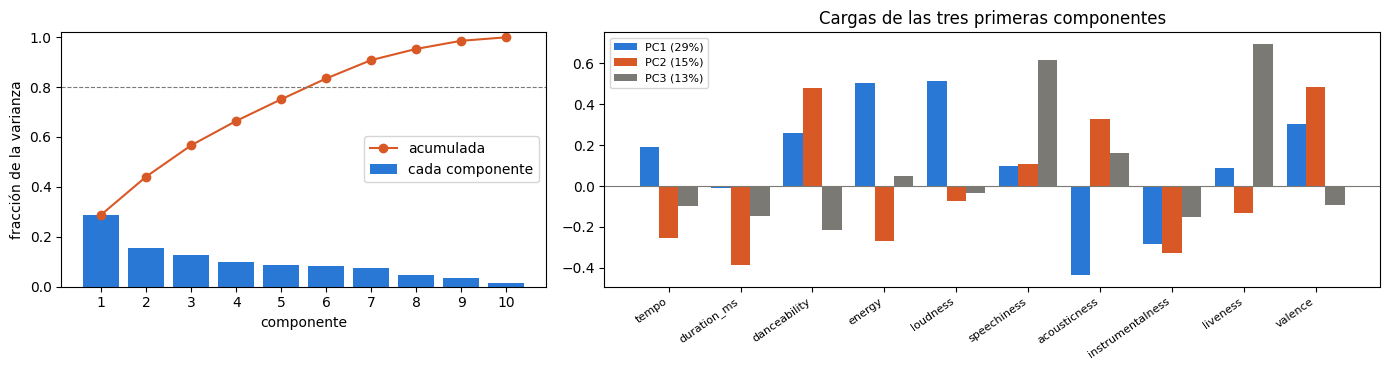

,varianza acumulada
PC1–PC1,0.289
PC1–PC2,0.441
PC1–PC3,0.567
PC1–PC4,0.664
PC1–PC5,0.751


In [32]:
def audio_escalado():
    """Primer paso de los pipelines sin etiqueta: las 10 numéricas, tempo sin ceros, escaladas."""
    return ColumnTransformer([
        ("tempo", Pipeline([("ceros", SimpleImputer(missing_values=0, strategy="median")), ("escalar", StandardScaler())]), ["tempo"]),
        ("resto", StandardScaler(), [c for c in NUMERICAS if c != "tempo"])],
        verbose_feature_names_out=False)

reducir = Pipeline([("audio", audio_escalado()), ("pca", PCA(random_state=SEMILLA))]).fit(X_train)
NOMBRES_AUDIO = list(reducir["audio"].get_feature_names_out())
varianza = reducir["pca"].explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
x = np.arange(1, len(varianza) + 1)
axes[0].bar(x, varianza, color=AZUL, label="cada componente")
axes[0].plot(x, varianza.cumsum(), marker="o", color=NARANJA, label="acumulada")
axes[0].axhline(0.8, color=GRIS, ls="--", lw=0.8)
axes[0].set_xlabel("componente"); axes[0].set_ylabel("fracción de la varianza"); axes[0].set_ylim(0, 1.02)
axes[0].legend(loc="center right"); axes[0].set_xticks(x)

cargas = pd.DataFrame(reducir["pca"].components_[:3].T, index=NOMBRES_AUDIO, columns=["PC1", "PC2", "PC3"])
ancho = 0.27
for i, (pc, color) in enumerate(zip(cargas.columns, [AZUL, NARANJA, GRIS])):
    axes[1].bar(np.arange(len(cargas)) + (i - 1) * ancho, cargas[pc], width=ancho, color=color,
                label=f"{pc} ({varianza[i]:.0%})")
axes[1].axhline(0, color=GRIS, lw=0.8)
axes[1].set_xticks(range(len(cargas)), cargas.index, rotation=35, ha="right", fontsize=8)
axes[1].set_title("Cargas de las tres primeras componentes"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.Series(varianza.cumsum()[:5], index=[f"PC1–PC{i}" for i in range(1, 6)], name="varianza acumulada").round(3)

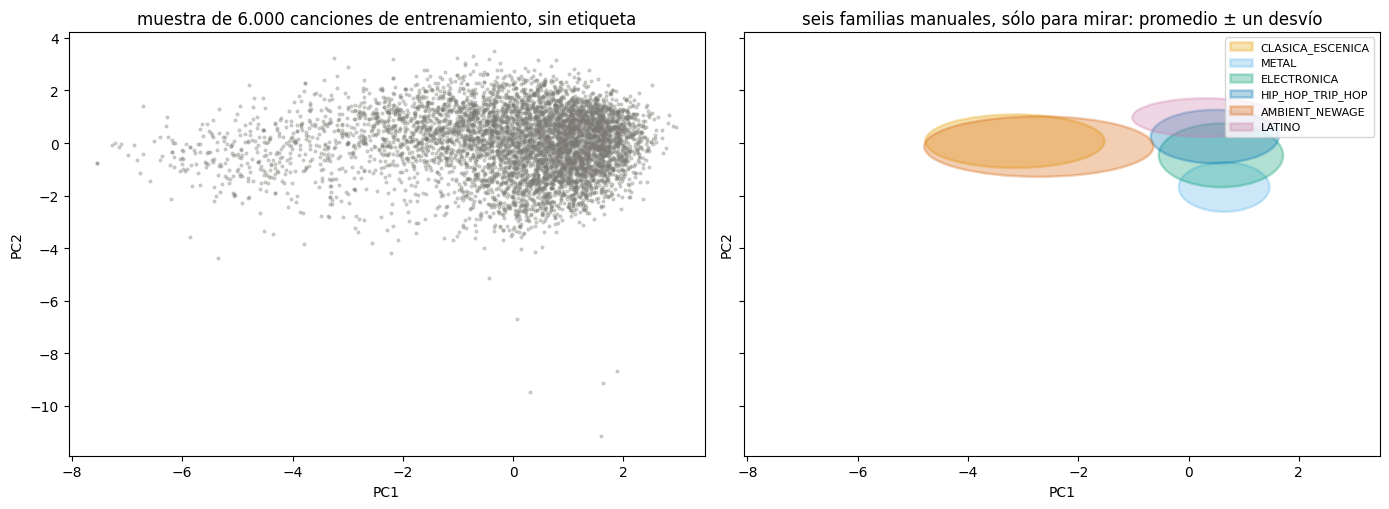

In [33]:
def elipse(ax, puntos, color, etiqueta):
    """Elipse centrada en el promedio del grupo, con semiejes de un desvío en cada componente."""
    ax.add_patch(Ellipse((puntos[:, 0].mean(), puntos[:, 1].mean()), 2 * puntos[:, 0].std(), 2 * puntos[:, 1].std(),
                         facecolor=color, alpha=0.30, edgecolor=color, lw=1.8, label=etiqueta))

proy = reducir.transform(X_train)[:, :2]
muestra = np.random.default_rng(SEMILLA).choice(len(proy), 6000, replace=False)
FAMILIAS_A_DIBUJAR = ["CLASICA_ESCENICA", "METAL", "ELECTRONICA", "HIP_HOP_TRIP_HOP", "AMBIENT_NEWAGE", "LATINO"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
axes[0].scatter(proy[muestra, 0], proy[muestra, 1], s=4, alpha=0.3, color=GRIS)
axes[0].set_title("muestra de 6.000 canciones de entrenamiento, sin etiqueta")
familia_manual_train = y_train.map(MAPA_MANUAL).to_numpy()
for color, fam in zip(OKABE_ITO, FAMILIAS_A_DIBUJAR):
    elipse(axes[1], proy[familia_manual_train == fam], color, fam)
axes[1].legend(fontsize=8, loc="upper right")
axes[1].set_title("seis familias manuales, sólo para mirar: promedio ± un desvío")
for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

**Lectura.** ✏️ Anotar cuántas componentes hacen falta para el 80 %: con columnas poco correlacionadas entre sí hacen falta varias, a diferencia de las 34 habilidades del FIFA. A la izquierda no hay grupos a la vista: una sola nube. A la derecha, las elipses de las familias manuales **se pisan** salvo las extremas (clásica, metal): el mismo degradé que la Práctica 3 encontró en los jugadores de campo.

### 10.2 k-means sobre canciones: por qué no sirve como objetivo

El `KMeansAuto` de la Práctica 3: un estimador que en `fit` prueba cada *k*, mide el silhouette (sobre una muestra) y se queda con el mejor, dejando la decisión en `k_` y la tabla en `barrido_`. La inercia se grafica desde *k* = 1, porque sin ese punto no se ve si hay codo.

k elegido sobre canciones: 2


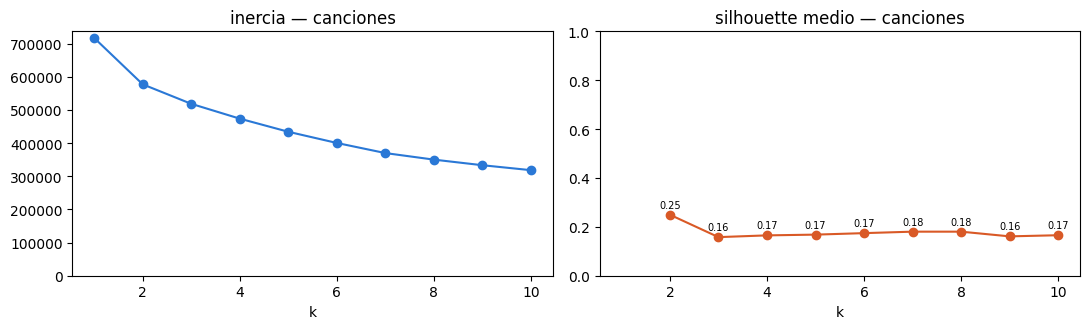

In [34]:
class KMeansAuto(BaseEstimator, TransformerMixin):
    """k-means que elige k solo: ajusta uno por cada k de ks y se queda con el de mayor silhouette medio."""

    def __init__(self, ks=range(2, 11), muestra=5000):
        self.ks = ks
        self.muestra = muestra

    def fit(self, X, y=None):
        X = np.asarray(X)
        tam = self.muestra if (self.muestra is not None and self.muestra < len(X)) else None
        modelos, filas = {}, {1: {"inercia": ((X - X.mean(axis=0)) ** 2).sum(), "silhouette": np.nan}}
        for k in self.ks:
            modelos[k] = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
            filas[k] = {"inercia": modelos[k].inertia_,
                        "silhouette": silhouette_score(X, modelos[k].labels_, sample_size=tam, random_state=SEMILLA)}
        self.barrido_ = pd.DataFrame(filas).T.rename_axis("k")
        self.k_ = int(self.barrido_["silhouette"].idxmax())
        self.kmeans_ = modelos[self.k_]
        self.labels_, self.cluster_centers_ = self.kmeans_.labels_, self.kmeans_.cluster_centers_
        return self

    def predict(self, X):
        return self.kmeans_.predict(np.asarray(X))

    def transform(self, X):
        return self.kmeans_.transform(np.asarray(X))


def graficar_barrido(barrido, titulo=""):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
    ax1.plot(barrido.index, barrido["inercia"], marker="o", color=AZUL)
    ax1.set_title(f"inercia {titulo}"); ax1.set_xlabel("k"); ax1.set_ylim(0)
    s = barrido["silhouette"].dropna()
    ax2.plot(s.index, s, marker="o", color=NARANJA)
    ax2.set_title(f"silhouette medio {titulo}"); ax2.set_xlabel("k"); ax2.set_ylim(0, 1); ax2.set_xlim(ax1.get_xlim())
    for k, v in s.items():
        ax2.annotate(f"{v:.2f}", (k, v), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=7)
    plt.tight_layout()
    plt.show()


agrupar_pistas = Pipeline([("audio", audio_escalado()), ("kmeans", KMeansAuto(ks=range(2, 11)))]).fit(X_train)
print("k elegido sobre canciones:", agrupar_pistas["kmeans"].k_)
graficar_barrido(agrupar_pistas["kmeans"].barrido_, "— canciones")

Ahora la prueba del círculo. El mismo árbol de decisión (con el mismo primer paso) se entrena dos veces con los mismos folds: una para predecir el **cluster** de cada canción, otra para predecir su **género**.

In [35]:
cluster_pista = pd.Series(agrupar_pistas.predict(X_train), index=X_train.index)
arbol_demo = Pipeline([("audio", audio_escalado()), ("clasificador", DecisionTreeClassifier(max_depth=12, random_state=SEMILLA))])

pd.DataFrame({
    f"cluster de k-means sobre canciones (k = {agrupar_pistas['kmeans'].k_})":
        {"clases": cluster_pista.nunique(),
         "F1 macro CV": cross_val_score(arbol_demo, X_train, cluster_pista, cv=CV_SPLITS, scoring="f1_macro").mean()},
    "género (113)":
        {"clases": y_train.nunique(),
         "F1 macro CV": cross_val_score(arbol_demo, X_train, y_train, cv=CV_SPLITS, scoring="f1_macro").mean()},
}).T.round(3)

,clases,F1 macro CV
cluster de k-means sobre canciones (k = 2),2.0,0.958
género (113),113.0,0.132


**Lectura.** ✏️ El árbol predice el cluster con F1 cercano a 1 y el género con un F1 de alrededor de 0,1. No es que los clusters sean «mejores clases»: el cluster es una función de las mismas `X`, y el árbol sólo aprende a recalcular a k-means. Usarlo como objetivo daría un número espectacular que no contesta nada sobre géneros. Por eso **se agrupan géneros, no canciones**.

### 10.3 k-means sobre géneros: 113 perfiles, *k* familias

La unidad pasa a ser el género. Cada uno se representa con su perfil promedio de entrenamiento (las 10 numéricas, sección 2.4). El pipeline es el de la Práctica 3: escalar y agrupar, con `KMeansAuto` probando *k* de 2 a 15. Con 113 puntos el silhouette se calcula con todos.

k elegido por silhouette sobre géneros: 2


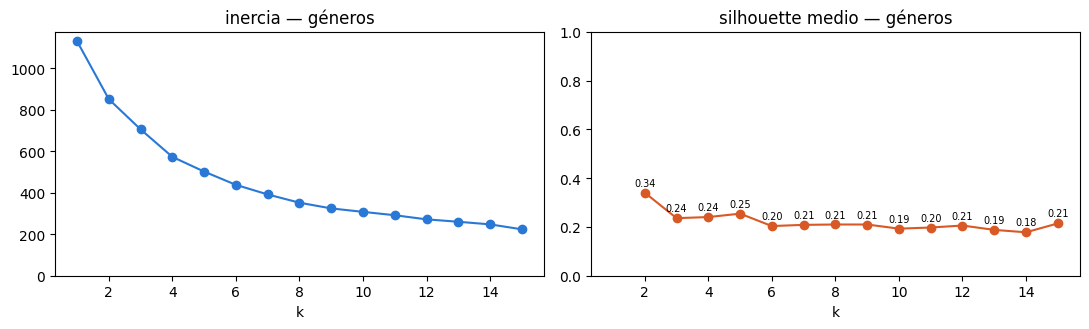

k,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
inercia,1130.0,850.621,705.169,572.648,501.791,437.970,391.668,351.894,324.373,307.727,291.557,271.683,260.034,247.460,223.673
silhouette,NaN,0.340,0.236,0.241,0.254,0.204,0.209,0.210,0.210,0.193,0.198,0.206,0.188,0.178,0.214


In [36]:
perfiles = perfiles_train[NUMERICAS]          # 113 × 10, promedios del entrenamiento
agrupar_generos = Pipeline([("escalar", StandardScaler()),
                            ("kmeans", KMeansAuto(ks=range(2, 16), muestra=None))]).fit(perfiles)
K_SIL = agrupar_generos["kmeans"].k_
print("k elegido por silhouette sobre géneros:", K_SIL)
graficar_barrido(agrupar_generos["kmeans"].barrido_, "— géneros")
agrupar_generos["kmeans"].barrido_.T.round(3)

**Lectura.** Con los datos reales el silhouette es **0,34 con k = 2** y queda entre 0,19 y 0,24 para todo k de 3 a 15, y la inercia no muestra un codo nítido (✏️ verificar en la salida; son los valores de nuestra exploración previa). Es la firma de un **degradé**, no de grupos: 113 géneros que se pueden cortar en dos con algo de limpieza, y en más de dos casi da lo mismo dónde. El paso automático elige k = 2, que coincide con uno de los dos valores propuestos.

Aviso: familias sin nombre por contenido, se deja el código: ['K10-05']


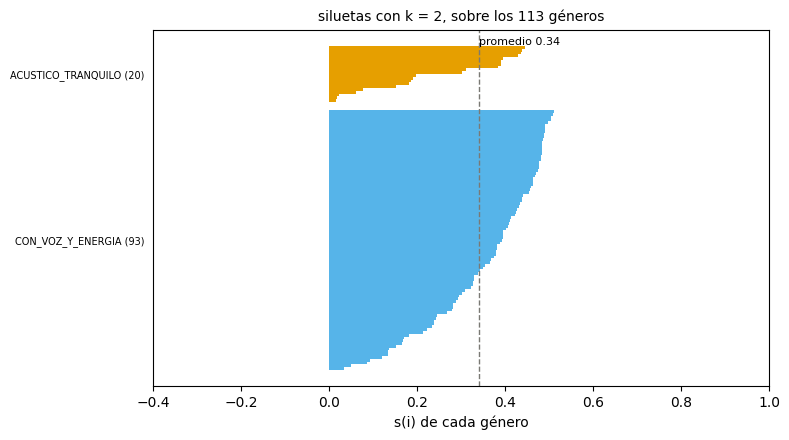

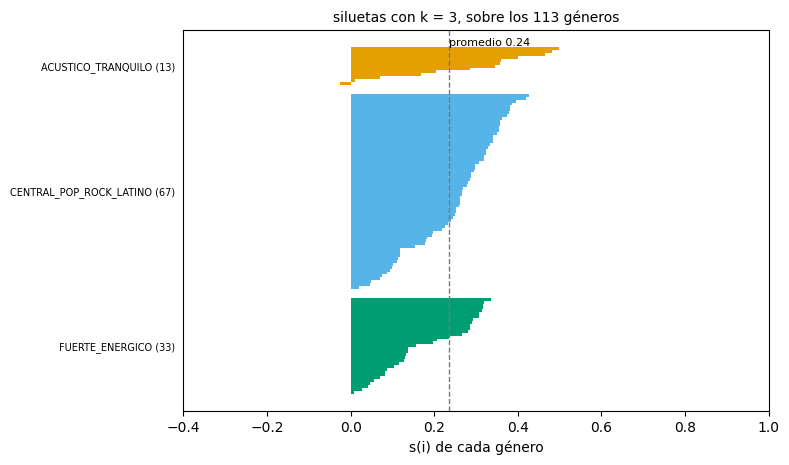

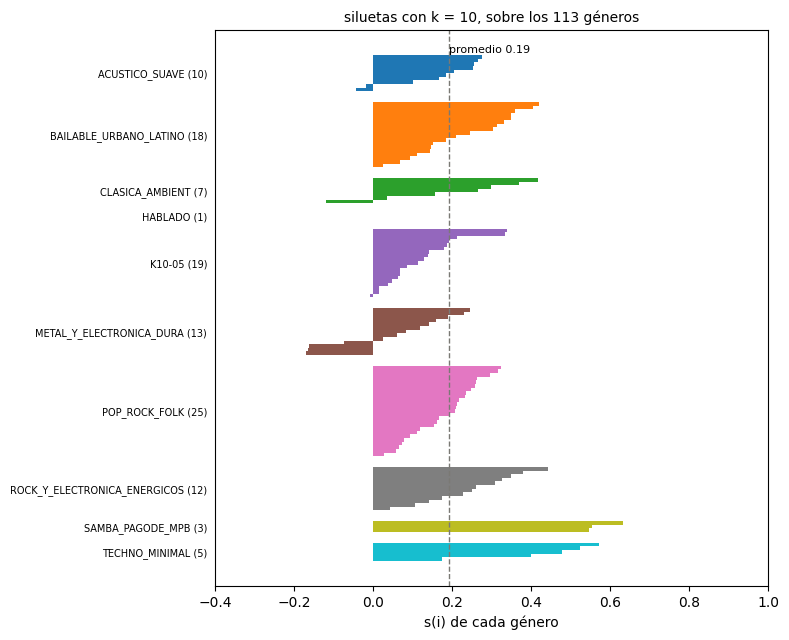

In [37]:
def familias_kmeans(k):
    """Mapa género → familia con k-means sobre los perfiles escalados.
    La numeración es estable: K{k}-01 es la familia de menor energy promedio."""
    p = Pipeline([("escalar", StandardScaler()),
                  ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=SEMILLA))]).fit(perfiles)
    etiquetas = pd.Series(p["kmeans"].labels_, index=perfiles.index)
    orden = perfiles_z.groupby(etiquetas)["energy"].mean().sort_values().index
    return etiquetas.map({viejo: f"K{k}-{i + 1:02d}" for i, viejo in enumerate(orden)}).rename(f"k-means k={k}"), p


def describir(mapa):
    """Una fila por familia: tamaño, los tres rasgos que más la apartan del promedio, y sus géneros."""
    filas = []
    for familia, generos in mapa.groupby(mapa):
        z = perfiles_z.loc[generos.index].mean()
        rasgos = ", ".join(f"{'+' if z[c] > 0 else '−'}{c}" for c in z.abs().sort_values(ascending=False).index[:3])
        filas.append({"Familia": familia, "N° géneros": len(generos),
                      "Canciones (train)": int(y_train.isin(generos.index).sum()),
                      "Rasgos (z medio)": rasgos, "Géneros": ", ".join(sorted(generos.index))})
    return pd.DataFrame(filas).set_index("Familia")


def graficar_siluetas(Z, grupos, titulo):
    """El gráfico de Rousseeuw: cada género es una barra de largo s(i), apiladas por familia y ordenadas."""
    s = silhouette_samples(Z, grupos)
    fig, ax = plt.subplots(figsize=(8, 4 + 0.25 * len(set(grupos)))); y0 = 0
    for i, g in enumerate(sorted(set(grupos))):
        valores = np.sort(s[grupos == g])[::-1]
        ax.barh(np.arange(y0, y0 + len(valores)), valores, height=1, color=colores(len(set(grupos)))[i])
        ax.text(-0.42, y0 + len(valores) / 2, f"{g} ({len(valores)})", ha="right", va="center", fontsize=7)
        y0 += len(valores) + 3
    ax.axvline(s.mean(), color=GRIS, ls="--", lw=1)
    ax.annotate(f"promedio {s.mean():.2f}", (s.mean(), -1), fontsize=8, ha="left")
    ax.set_xlabel("s(i) de cada género"); ax.set_yticks([]); ax.set_xlim(-0.4, 1)
    ax.set_title(titulo, fontsize=10); ax.invert_yaxis()
    plt.tight_layout()
    plt.show()


# Nombres por contenido: cada familia toma el nombre cuyos géneros representativos contiene en mayor número.
# Así el nombre sigue al contenido aunque k-means numere distinto en otra versión de scikit-learn.
NOMBRES_FAMILIAS = {
    2: {"ACUSTICO_TRANQUILO": ["classical", "piano", "ambient", "sleep", "jazz"],
        "CON_VOZ_Y_ENERGIA": ["pop", "rock", "metal", "house", "hip-hop"]},
    3: {"ACUSTICO_TRANQUILO": ["classical", "piano", "ambient", "sleep", "jazz"],
        "FUERTE_ENERGICO": ["metal", "death-metal", "techno", "trance", "punk"],
        "CENTRAL_POP_ROCK_LATINO": ["pop", "rock", "latin", "country", "hip-hop"]},
    10: {"METAL_Y_ELECTRONICA_DURA": ["black-metal", "death-metal", "metal", "grindcore", "hardstyle", "trance", "dubstep"],
         "SLEEP_RUIDO": ["sleep"],
         "ACUSTICO_SUAVE": ["piano", "jazz", "guitar", "opera", "chill", "study"],
         "POP_ROCK_FOLK": ["pop", "rock", "country", "folk", "acoustic", "indie"],
         "ROCK_Y_ELECTRONICA_ENERGICOS": ["alt-rock", "punk", "hard-rock", "edm", "deep-house", "emo", "punk-rock"],
         "BAILABLE_URBANO_LATINO": ["house", "hip-hop", "reggaeton", "latin", "dance", "funk", "salsa"],
         "CLASICA_AMBIENT": ["classical", "ambient", "new-age"],
         "HABLADO": ["comedy"],
         "SAMBA_PAGODE_MPB": ["samba", "pagode", "sertanejo", "mpb"],
         "TECHNO_MINIMAL": ["techno", "minimal-techno", "detroit-techno", "chicago-house"]},
}


def nombrar(mapa, nombres):
    """Asigna a cada familia el nombre con más géneros ancla adentro (asignación golosa, sin repetir nombres).
    Una familia sin ancla conserva su código: se avisa, porque entonces el nombre habría que revisarlo."""
    familias = list(mapa.unique())
    pares = sorted(((len(set(mapa[mapa == f].index) & set(anclas)), f, n)
                    for f in familias for n, anclas in nombres.items()), key=lambda t: -t[0])
    asignado, usados = {}, set()
    for coincidencias, f, n in pares:
        if coincidencias > 0 and f not in asignado and n not in usados:
            asignado[f] = n
            usados.add(n)
    sin_nombre = [f for f in familias if f not in asignado]
    if sin_nombre:
        print("Aviso: familias sin nombre por contenido, se deja el código:", sin_nombre)
    return mapa.map(lambda f: asignado.get(f, f))


def colores(n):
    return OKABE_ITO[:n] if n <= len(OKABE_ITO) else [plt.cm.tab10(i % 10) for i in range(n)]


K_PEDIDOS = sorted({2, 3, K_SIL})            # los k pedidos (2 y 3) y el del silhouette
K_DESCRIPTOS = K_PEDIDOS + [10]              # k = 10: familias con una granularidad útil para la app
MAPAS_KMEANS = {k: familias_kmeans(k)[0] for k in K_DESCRIPTOS + [20]}
for k, nombres in NOMBRES_FAMILIAS.items():
    if k in MAPAS_KMEANS:
        MAPAS_KMEANS[k] = nombrar(MAPAS_KMEANS[k], nombres).rename(f"k-means k={k}")
Z_perfiles = StandardScaler().fit_transform(perfiles)
for k in K_DESCRIPTOS:
    graficar_siluetas(Z_perfiles, MAPAS_KMEANS[k].loc[perfiles.index].to_numpy(), f"siluetas con k = {k}, sobre los 113 géneros")

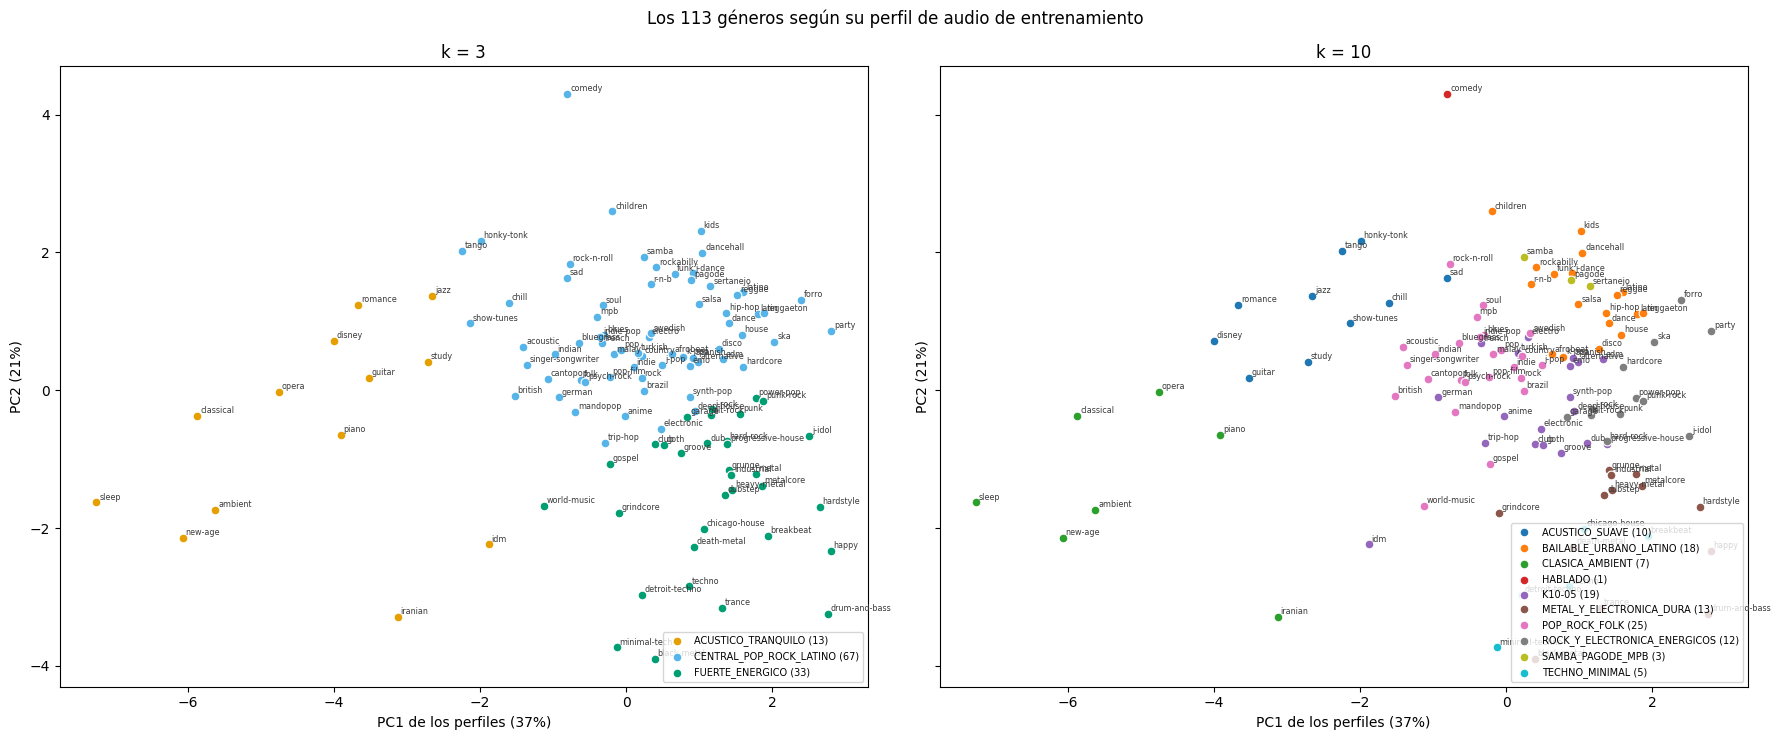

,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
PC1,0.05,0.26,0.47,0.50,0.06,-0.43,-0.25,0.06,0.24,0.39
PC2,-0.46,0.29,-0.19,0.04,0.22,0.30,-0.45,0.13,0.48,-0.27


In [38]:
# los géneros en el plano de las dos primeras componentes de sus perfiles, coloreados por familia
pca_generos = Pipeline([("escalar", StandardScaler()), ("pca", PCA(n_components=2, random_state=SEMILLA))]).fit(perfiles)
coords = pd.DataFrame(pca_generos.transform(perfiles), index=perfiles.index, columns=["PC1", "PC2"])
var_g = pca_generos["pca"].explained_variance_ratio_

k_dibujo = [3, 10]
fig, axes = plt.subplots(1, len(k_dibujo), figsize=(18, 7.5), sharex=True, sharey=True)
for ax, k in zip(axes, k_dibujo):
    mapa = MAPAS_KMEANS[k]
    paleta = colores(mapa.nunique())
    for i, fam in enumerate(sorted(mapa.unique())):
        gens = mapa[mapa == fam].index
        ax.scatter(coords.loc[gens, "PC1"], coords.loc[gens, "PC2"], s=40, color=paleta[i], label=f"{fam} ({len(gens)})",
                   edgecolors="white", linewidths=0.8)
    for g, (px, py) in coords.iterrows():
        ax.annotate(g, (px, py), fontsize=5.8, xytext=(2, 2), textcoords="offset points", color="#3a3a3a")
    ax.set_title(f"k = {k}")
    ax.set_xlabel(f"PC1 de los perfiles ({var_g[0]:.0%})"); ax.set_ylabel(f"PC2 ({var_g[1]:.0%})")
    ax.legend(fontsize=7, loc="lower right")
fig.suptitle("Los 113 géneros según su perfil de audio de entrenamiento", fontsize=12)
plt.tight_layout()
plt.show()

cargas_g = pd.DataFrame(pca_generos["pca"].components_.T, index=NUMERICAS, columns=["PC1", "PC2"])
cargas_g.round(2).T

**Además de k = 2 y 3, k = 10.** Dos o tres familias son demasiado gruesas para que la app diga algo útil, así que se agrega k = 10 y se le pone **nombre** a cada familia según lo que representa. El nombre no se fija a mano por número de cluster (k-means puede numerar distinto en otra versión de scikit-learn): cada familia recibe el nombre cuyos **géneros ancla** contiene en mayor número (`NOMBRES_FAMILIAS`). Si alguna queda sin ancla, conserva el código y se avisa, y hay que revisar el nombre.

Una advertencia que vale para leer los nombres: k-means agrupa por **cómo suena** (energía, si es acústica, si es bailable), no por tradición o mercado. Por eso los nombres son sonoros («bailable», «energético») y algunas familias mezclan géneros que un humano separaría, como `spanish` dentro de rock y electrónica energéticos, o `kids` y `children` dentro de lo bailable.

In [39]:
for k in K_DESCRIPTOS:
    print(f"Familias con k = {k}")
    display(describir(MAPAS_KMEANS[k]))
    display(perfiles_z.groupby(MAPAS_KMEANS[k]).mean().round(2).rename_axis(f"z medio, k = {k}"))

Familias con k = 2


,N° géneros,Canciones (train),Rasgos (z medio),Géneros
Familia,,,,
ACUSTICO_TRANQUILO,20,14384,"−loudness, −energy, +acousticness","acoustic, ambient, british, chill, classical, disney, guitar, honky-tonk, idm, iranian, jazz, new-age, opera, piano, romance, show-tunes..."
CON_VOZ_Y_ENERGIA,93,57317,"+loudness, +energy, −acousticness","afrobeat, alt-rock, alternative, anime, black-metal, bluegrass, blues, brazil, breakbeat, cantopop, chicago-house, children, club, comed..."


,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
"z medio, k = 2",,,,,,,,,,
ACUSTICO_TRANQUILO,-0.35,-0.89,-1.62,-1.63,-0.30,1.52,0.95,-0.38,-0.81,-1.05
CON_VOZ_Y_ENERGIA,0.08,0.19,0.35,0.35,0.07,-0.33,-0.20,0.08,0.17,0.23


Familias con k = 3


,N° géneros,Canciones (train),Rasgos (z medio),Géneros
Familia,,,,
ACUSTICO_TRANQUILO,13,9409,"−loudness, −energy, +acousticness","ambient, classical, disney, guitar, idm, iranian, jazz, new-age, opera, piano, romance, sleep, study"
CENTRAL_POP_ROCK_LATINO,67,41167,"+valence, −instrumentalness, +danceability","acoustic, afrobeat, alternative, anime, bluegrass, blues, brazil, british, cantopop, children, chill, comedy, country, dance, dancehall,..."
FUERTE_ENERGICO,33,21125,"−acousticness, +tempo, +energy","alt-rock, black-metal, breakbeat, chicago-house, club, death-metal, detroit-techno, drum-and-bass, dub, dubstep, garage, gospel, goth, g..."


,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
"z medio, k = 3",,,,,,,,,,
ACUSTICO_TRANQUILO,-0.14,-1.29,-1.79,-2.17,-0.35,1.66,1.61,-0.35,-1.20,-1.30
CENTRAL_POP_ROCK_LATINO,-0.29,0.44,-0.10,0.15,0.12,0.15,-0.47,0.01,0.49,-0.19
FUERTE_ENERGICO,0.65,-0.38,0.90,0.55,-0.11,-0.96,0.33,0.11,-0.51,0.90


Familias con k = 10


,N° géneros,Canciones (train),Rasgos (z medio),Géneros
Familia,,,,
ACUSTICO_SUAVE,10,6978,"−energy, +acousticness, −duration_ms","chill, disney, guitar, honky-tonk, jazz, romance, sad, show-tunes, study, tango"
BAILABLE_URBANO_LATINO,18,10297,"+valence, +danceability, −instrumentalness","afrobeat, children, dance, dancehall, disco, funk, hip-hop, house, j-dance, k-pop, kids, latin, latino, r-n-b, reggae, reggaeton, rockab..."
CLASICA_AMBIENT,7,5179,"−loudness, −danceability, −energy","ambient, classical, iranian, new-age, opera, piano, sleep"
HABLADO,1,783,"+speechiness, +liveness, −tempo",comedy
K10-05,19,12558,"−acousticness, +danceability, −valence","alternative, anime, club, deep-house, dub, edm, electro, electronic, emo, french, german, goth, groove, idm, progressive-house, spanish,..."
METAL_Y_ELECTRONICA_DURA,13,8295,"+tempo, +energy, −acousticness","black-metal, death-metal, drum-and-bass, dubstep, grindcore, grunge, happy, hardstyle, heavy-metal, industrial, metal, metalcore, trance"
POP_ROCK_FOLK,25,14975,"−instrumentalness, −energy, +acousticness","acoustic, bluegrass, blues, brazil, british, cantopop, country, folk, gospel, indian, indie, indie-pop, j-pop, malay, mandopop, mpb, pop..."
ROCK_Y_ELECTRONICA_ENERGICOS,12,7394,"+tempo, +energy, +valence","alt-rock, forro, garage, hard-rock, hardcore, j-idol, j-rock, party, power-pop, punk, punk-rock, ska"
SAMBA_PAGODE_MPB,3,1846,"+liveness, +valence, +acousticness","pagode, samba, sertanejo"


,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
"z medio, k = 10",,,,,,,,,,
ACUSTICO_SUAVE,-1.13,-0.08,-1.58,-1.04,-0.08,1.57,0.37,-0.43,-0.12,-0.95
BAILABLE_URBANO_LATINO,-0.44,1.12,0.23,0.49,0.38,-0.22,-0.59,-0.42,1.15,-0.23
CLASICA_AMBIENT,0.37,-2.09,-1.96,-2.85,-0.46,1.77,1.92,-0.16,-1.82,-1.61
HABLADO,-0.05,0.10,0.39,-0.64,9.39,1.77,-0.73,5.84,-0.16,-2.53
K10-05,-0.08,0.32,0.23,0.22,-0.00,-0.45,0.09,-0.22,-0.28,0.02
METAL_Y_ELECTRONICA_DURA,0.36,-0.95,1.35,0.83,0.13,-1.21,0.37,0.40,-1.10,1.36
POP_ROCK_FOLK,0.12,-0.10,-0.51,-0.08,-0.40,0.43,-0.56,-0.19,0.03,-0.20
ROCK_Y_ELECTRONICA_ENERGICOS,-0.20,-0.21,0.93,0.72,-0.19,-0.75,-0.52,0.28,0.82,0.94
SAMBA_PAGODE_MPB,-0.20,0.08,0.37,0.36,-0.19,0.77,-0.73,3.68,1.33,0.03


**Lectura.** Con los perfiles de entrenamiento:

- **k = 2:** `ACUSTICO_TRANQUILO` (~20 géneros: classical, piano, ambient, sleep, jazz…) contra `CON_VOZ_Y_ENERGIA` (el resto).
- **k = 3:** `ACUSTICO_TRANQUILO`, `FUERTE_ENERGICO` (metal, punk, electrónica dura) y `CENTRAL_POP_ROCK_LATINO`, que se lleva más de la mitad de los géneros.
- **k = 10** (medido en nuestra exploración; ✏️ confirmar con la tabla):

| Familia | Géneros | Qué representa |
|---|---|---|
| `POP_ROCK_FOLK` | 29 | pop, rock, country, folk, indie, k/j/c-pop, blues, soul… el «centro» sin rasgo extremo |
| `ROCK_Y_ELECTRONICA_ENERGICOS` | 25 | alt-rock, punk, hard-rock, emo, edm, deep-house, progressive-house, ska… |
| `BAILABLE_URBANO_LATINO` | 20 | house, hip-hop, reggaetón, latin, salsa, funk, disco, dancehall… |
| `METAL_Y_ELECTRONICA_DURA` | 12 | metal, black/death-metal, grindcore, hardstyle, trance, dubstep, drum-and-bass |
| `ACUSTICO_SUAVE` | 11 | piano, jazz, guitar, opera, chill, study, tango, show-tunes |
| `TECHNO_MINIMAL` | 6 | techno, minimal/detroit-techno, chicago-house, breakbeat, idm |
| `CLASICA_AMBIENT` | 4 | classical, ambient, new-age, iranian |
| `SAMBA_PAGODE_MPB` | 4 | samba, pagode, sertanejo, mpb |
| `HABLADO` | 1 | comedy |
| `SLEEP_RUIDO` | 1 | sleep |

Los extremos salen limpios (clásica/ambient, techno, metal, brasileño). El centro no: pop, rock y country **suenan parecido en estas 10 columnas** y caen juntos, y la electrónica se reparte en tres familias según tempo y energía. Dos familias de un solo género (`HABLADO`, `SLEEP_RUIDO`) son los mismos que DBSCAN deja como ruido: no se parecen a nadie.

### 10.4 DBSCAN sobre géneros: los que no se parecen a nadie

La otra definición de grupo (Práctica 3, sección 3.3): zonas densas separadas por huecos, con ruido. Con 113 puntos en 10 dimensiones se usa `min_samples = 4`, y `eps` se fija con una regla escrita antes de mirar: el **percentil 90** de la distancia de cada género a su cuarto vecino.

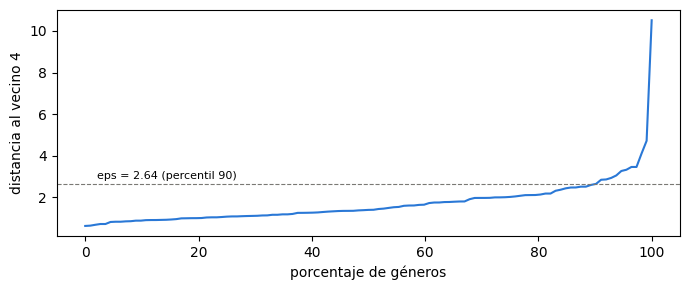

,grupos,ruido,tamaños
eps,,,
1.00,3,78,"24, 7, 4"
1.50,1,45,68
2.00,2,18,"92, 3"
2.50,1,6,107
2.64,1,5,108


Géneros que DBSCAN deja como ruido con eps = 2.64:


,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,rasgo_principal
track_genre,,,,,,,,,,,
comedy,-0.05,0.10,0.39,-0.64,9.39,1.77,-0.73,5.84,-0.16,-2.53,speechiness
grindcore,-2.13,-2.65,1.68,0.57,0.69,-1.33,1.82,0.87,-1.75,-0.38,danceability
iranian,2.08,-2.38,-0.58,-1.47,0.05,0.42,2.09,-0.35,-2.21,-0.84,danceability
sleep,-0.99,-3.57,-1.76,-4.75,-0.42,1.49,2.74,1.94,-2.85,-2.92,loudness
study,-1.91,1.05,-1.37,-0.78,0.15,0.94,3.03,-0.71,-0.51,-1.39,instrumentalness


In [40]:
MIN_VECINOS = 4
distancias = np.sort(NearestNeighbors(n_neighbors=MIN_VECINOS).fit(Z_perfiles).kneighbors(Z_perfiles)[0][:, -1])
EPS = float(np.percentile(distancias, 90))

barrido_eps = {}
for eps in sorted({1.0, 1.5, 2.0, 2.5, round(EPS, 2)}):
    etq = pd.Series(DBSCAN(eps=eps, min_samples=MIN_VECINOS).fit(Z_perfiles).labels_)
    tam = etq[etq >= 0].value_counts()
    barrido_eps[eps] = {"grupos": len(tam), "ruido": int((etq == -1).sum()), "tamaños": ", ".join(map(str, tam.values[:4]))}

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.linspace(0, 100, len(distancias)), distancias, color=AZUL)
ax.axhline(EPS, color=GRIS, ls="--", lw=0.8)
ax.annotate(f"eps = {EPS:.2f} (percentil 90)", (2, EPS), textcoords="offset points", xytext=(0, 4), fontsize=8)
ax.set_xlabel("porcentaje de géneros"); ax.set_ylabel(f"distancia al vecino {MIN_VECINOS}")
plt.tight_layout()
plt.show()
display(pd.DataFrame(barrido_eps).T.rename_axis("eps"))

etiquetas_db = pd.Series(DBSCAN(eps=EPS, min_samples=MIN_VECINOS).fit(Z_perfiles).labels_, index=perfiles.index)
ruido = etiquetas_db[etiquetas_db == -1].index
print(f"Géneros que DBSCAN deja como ruido con eps = {EPS:.2f}:")
perfiles_z.loc[ruido].assign(rasgo_principal=perfiles_z.loc[ruido].abs().idxmax(axis=1)).round(2)

**Lectura.** ✏️ Listar los géneros de ruido: son los que no se parecen a ningún otro, con un rasgo extremo (por ejemplo `comedy` por `speechiness`, `sleep` por `instrumentalness` y baja energía). En la exploración, k-means con k ≥ 4 ya dedicaba un cluster entero a un solo género: DBSCAN lo explica sin forzar una familia de uno.

### 10.5 Familias de k-means contra familias manuales

¿Cuánto se parece el agrupamiento por audio al catálogo a mano? Tabla cruzada para *k* = 3 y el **índice de Rand ajustado** (ARI: 0 = coincidencia de azar, 1 = idénticos) para cada *k*, incluida la comparación justa en granularidad: **k-means con k = 20 contra las 20 familias manuales**.

In [41]:
display(pd.crosstab(MAPA_MANUAL.rename("familia manual"), MAPAS_KMEANS[3].loc[MAPA_MANUAL.index]))
pd.Series({f"ARI manual vs k-means k={k}": adjusted_rand_score(MAPA_MANUAL.sort_index(), MAPAS_KMEANS[k].sort_index())
           for k in MAPAS_KMEANS}).round(3)

k-means k=3,ACUSTICO_TRANQUILO,CENTRAL_POP_ROCK_LATINO,FUERTE_ENERGICO
familia manual,,,
ACUSTICO_INSTRUMENTAL,2,1,0
AMBIENT_NEWAGE,2,1,0
BRASILENO,0,6,0
CLASICA_ESCENICA,2,0,0
ELECTRONICA,1,8,12
FOLK_COUNTRY,0,5,0
HIP_HOP_TRIP_HOP,0,2,0
INFANTIL_Y_MEDIOS,1,4,0
JAZZ_BLUES,1,1,0


,0
ARI manual vs k-means k=2,0.029
ARI manual vs k-means k=3,0.026
ARI manual vs k-means k=10,0.101
ARI manual vs k-means k=20,0.143


**Lectura.** ✏️ Si el ARI entre k-means k=20 y el manual es bajo (cerca de 0), el catálogo a mano **no sigue el audio**: agrupa por historia, idioma o mercado (`REGIONAL_IDIOMA`, `MISCELANEO`, `INFANTIL_Y_MEDIOS`). La tabla cruzada muestra qué familias manuales se reparten entre varias de k-means (las heterogéneas) y cuáles caen enteras en una (las acústicamente coherentes, como `METAL` o `CLASICA_ESCENICA`).

## Parte 11 — Entrenar con la familia como objetivo: ¿mejora de verdad?

La pregunta parece fácil y tiene una trampa: **una métrica con 3 clases no se compara con una de 113**. Acertar al azar es 33 % contra 0,9 %; cualquier agrupamiento «mejora» la accuracy. Para contestar si el modelo mejoró hay que comparar contra referencias que tengan **la misma cantidad de clases**:

1. **El piso de cada objetivo**: un `DummyClassifier` con las mismas clases. Se informa la ganancia de F1 macro sobre ese piso y el **κ de Cohen**, que descuenta el acierto esperable por azar.
2. **Un agrupamiento al azar con la misma forma**: los mismos *k* y la misma cantidad de géneros por familia, pero repartidos al azar (tres sorteos). Si las familias de k-means no se predicen mejor que familias sorteadas, el agrupamiento no aporta nada: sólo cambia la pregunta.
3. **El modelo de géneros agregado** («jerárquico»): las probabilidades del modelo de 113 géneros se suman por familia. Si entrenar directo con la familia no le gana a eso, no hace falta un modelo nuevo: alcanza con reetiquetar la salida del que ya existe.

Todo se mide con **validación cruzada sobre los mismos 5 folds** y el mismo pipeline congelado de la Parte 8 (clonado, sin entrenar). Los hiperparámetros se ajustaron para 113 géneros y se reutilizan sin retocar, para que la comparación sea entre objetivos y no entre ajustes; es una limitación que se declara.

In [42]:
X_sel = X_train[FEATURES_ELEGIDAS]

def proba_oof(objetivo):
    """Probabilidades de cada canción de entrenamiento, calculadas por el fold que no la vio."""
    proba = cross_val_predict(clone(modelo_final), X_sel, objetivo, cv=CV_SPLITS, method="predict_proba", n_jobs=N_JOBS_CV)
    return pd.DataFrame(proba, columns=np.sort(objetivo.unique()), index=objetivo.index)


def agregar_a_familias(proba_genero, mapa):
    """Suma las probabilidades de los géneros de cada familia."""
    return proba_genero.T.groupby(proba_genero.columns.map(mapa)).sum().T


def metricas(objetivo, proba, nombre, modo):
    pred = proba.idxmax(axis=1)
    piso = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_sel, objetivo, cv=CV_SPLITS)
    n = proba.shape[1]
    top = lambda k: top_k_accuracy_score(objetivo, proba.values, k=k, labels=proba.columns) if n > k else np.nan
    return {"Objetivo": nombre, "Modo": modo, "Clases": n,
            "F1 macro": f1_score(objetivo, pred, average="macro"),
            "F1 piso": f1_score(objetivo, piso, average="macro"),
            "Ganancia sobre piso": f1_score(objetivo, pred, average="macro") - f1_score(objetivo, piso, average="macro"),
            "Accuracy": accuracy_score(objetivo, pred), "Accuracy piso": accuracy_score(objetivo, piso),
            "Kappa": cohen_kappa_score(objetivo, pred), "Top-2": top(2), "Top-3": top(3)}


print("Géneros (113): 5 entrenamientos")
proba_genero_oof = proba_oof(y_train)
filas_familias = [metricas(y_train, proba_genero_oof, "Géneros (113)", "directo")]

AGRUPAMIENTOS = {f"k-means k={k}" + (" (silhouette)" if k == K_SIL else ""): MAPAS_KMEANS[k] for k in K_PEDIDOS}
AGRUPAMIENTOS["k-means k=10 (con nombres)"] = MAPAS_KMEANS[10]
AGRUPAMIENTOS["k-means k=20"] = MAPAS_KMEANS[20]
AGRUPAMIENTOS["Manual 20"] = MAPA_MANUAL

PROBAS_FAMILIA = {}
for nombre, mapa in AGRUPAMIENTOS.items():
    print(nombre, ": 5 entrenamientos")
    objetivo = y_train.map(mapa)
    PROBAS_FAMILIA[nombre] = proba_oof(objetivo)
    filas_familias.append(metricas(objetivo, PROBAS_FAMILIA[nombre], nombre, "directo"))
    filas_familias.append(metricas(objetivo, agregar_a_familias(proba_genero_oof, mapa), nombre, "jerárquico (géneros sumados)"))

tabla_familias = pd.DataFrame(filas_familias).set_index(["Objetivo", "Modo"])
tabla_familias.round(4)

Géneros (113): 5 entrenamientos
k-means k=2 (silhouette) : 5 entrenamientos
k-means k=3 : 5 entrenamientos
k-means k=10 (con nombres) : 5 entrenamientos
k-means k=20 : 5 entrenamientos
Manual 20 : 5 entrenamientos


Clases  F1 macro  F1 piso  Ganancia sobre piso  Accuracy  Accuracy piso   Kappa   Top-2   Top-3
Objetivo                   Modo                                                                                                                         
Géneros (113)              directo                          113    0.2252   0.0007               0.2245    0.2717         0.0104  0.2645  0.3776  0.4428
k-means k=2 (silhouette)   directo                            2    0.8133   0.4443               0.3691    0.8873         0.7994  0.6272     NaN     NaN
                           jerárquico (géneros sumados)       2    0.7969   0.4443               0.3526    0.8869         0.7994  0.5970     NaN     NaN
k-means k=3                directo                            3    0.7568   0.2432               0.5137    0.7884         0.5741  0.6201  0.9677     NaN
                           jerárquico (géneros sumados)       3    0.7478   0.2432               0.5047    0.7878         0.5741  0.6079  0.9662     NaN
k-means k=10 (con nombres) directo                           10    0.5830   0.0346               0.5484    0.5424         0.2089  0.4711  0.7476  0.8641
                           jerárquico (géneros sumados)      10    0.5816   0.0346               0.5470    0.5455         0.2089  0.4693  0.7473  0.8665
k-means k=20               directo                           20    0.4858   0.0107               0.4751    0.4417         0.1199  0.4037  0.6136  0.7226
                           jerárquico (géneros sumados)      20    0.4858   0.0107               0.4751    0.4426         0.1199  0.3990  0.6195  0.7287
Manual 20                  directo                           20    0.3288   0.0157               0.3131    0.4123         0.1866  0.3584  0.5522  0.6437
                           jerárquico (géneros sumados)      20    0.3106   0.0157               0.2949    0.4161         0.1866  0.3474  0.5572  0.6490

In [43]:
def agrupamiento_al_azar(mapa, semilla):
    """Las mismas familias con la misma cantidad de géneros cada una, repartidas al azar."""
    generos = mapa.index.to_numpy()
    return pd.Series(np.random.default_rng(semilla).permutation(mapa.to_numpy()), index=generos)

filas_azar = []
for k in [2, 3, 10]:
    for semilla in range(3):
        mapa_azar = agrupamiento_al_azar(MAPAS_KMEANS[k], semilla)
        print(f"Azar k={k}, sorteo {semilla + 1}: 5 entrenamientos")
        objetivo = y_train.map(mapa_azar)
        filas_azar.append({"k": k, "sorteo": semilla + 1, **metricas(objetivo, proba_oof(objetivo), f"azar k={k}", "directo")})
        filas_azar.append({"k": k, "sorteo": semilla + 1,
                           **metricas(objetivo, agregar_a_familias(proba_genero_oof, mapa_azar), f"azar k={k}", "jerárquico (géneros sumados)")})

tabla_azar = pd.DataFrame(filas_azar)
resumen_azar = tabla_azar.groupby(["k", "Modo"])[["F1 macro", "Ganancia sobre piso", "Accuracy", "Kappa"]].agg(["mean", "std"])
resumen_azar.round(4)

Azar k=2, sorteo 1: 5 entrenamientos
Azar k=2, sorteo 2: 5 entrenamientos
Azar k=2, sorteo 3: 5 entrenamientos
Azar k=3, sorteo 1: 5 entrenamientos
Azar k=3, sorteo 2: 5 entrenamientos
Azar k=3, sorteo 3: 5 entrenamientos
Azar k=10, sorteo 1: 5 entrenamientos
Azar k=10, sorteo 2: 5 entrenamientos
Azar k=10, sorteo 3: 5 entrenamientos


F1 macro         Ganancia sobre piso         Accuracy           Kappa        
                                    mean     std                mean     std     mean     std    mean     std
k  Modo                                                                                                      
2  directo                        0.5518  0.0235              0.1036  0.0258   0.8224  0.0073  0.1532  0.0361
   jerárquico (géneros sumados)   0.4968  0.0124              0.0485  0.0139   0.8196  0.0076  0.0736  0.0206
3  directo                        0.4634  0.0201              0.2157  0.0187   0.6353  0.0141  0.2275  0.0197
   jerárquico (géneros sumados)   0.3897  0.0183              0.1420  0.0168   0.6317  0.0136  0.1578  0.0203
10 directo                        0.3094  0.0160              0.2739  0.0170   0.3716  0.0133  0.2601  0.0156
   jerárquico (géneros sumados)   0.2823  0.0234              0.2469  0.0248   0.3754  0.0108  0.2469  0.0166

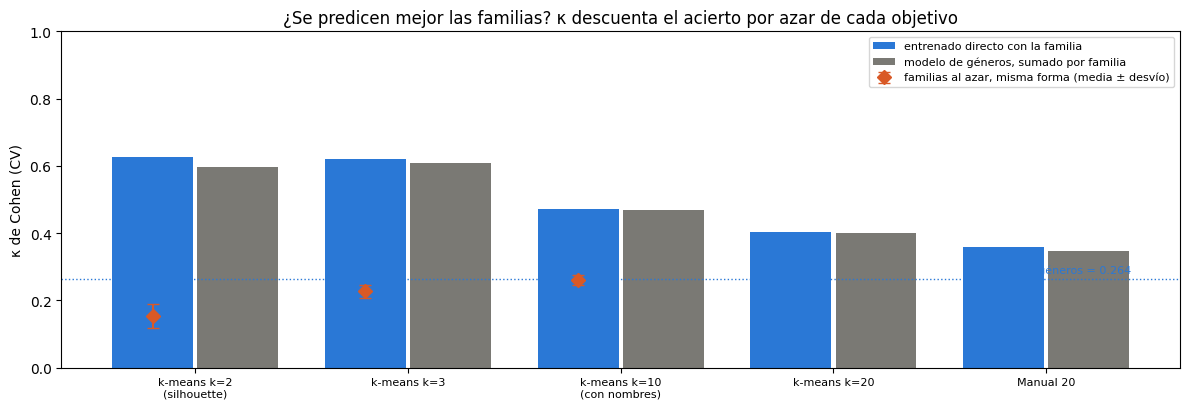

In [44]:
# κ por objetivo: directo contra jerárquico, con el azar de la misma forma como referencia
directo = tabla_familias.xs("directo", level="Modo")["Kappa"]
jerarquico = tabla_familias.xs("jerárquico (géneros sumados)", level="Modo")["Kappa"]
objetivos = list(jerarquico.index)

fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(objetivos))
ax.bar(x - 0.2, directo.loc[objetivos], width=0.38, color=AZUL, label="entrenado directo con la familia")
ax.bar(x + 0.2, jerarquico.loc[objetivos], width=0.38, color=GRIS, label="modelo de géneros, sumado por familia")
for k in [2, 3, 10]:
    nombre = next(o for o in objetivos if o.startswith(f"k-means k={k} ") or o == f"k-means k={k}")
    i = objetivos.index(nombre)
    az = tabla_azar[(tabla_azar["k"] == k) & (tabla_azar["Modo"] == "directo")]["Kappa"]
    ax.errorbar(i - 0.2, az.mean(), yerr=az.std(), fmt="D", color=NARANJA, capsize=4, markersize=7,
                label="familias al azar, misma forma (media ± desvío)" if k == 2 else None)
ax.axhline(directo.loc["Géneros (113)"], color=AZUL, ls=":", lw=1)
ax.annotate(f"κ de los 113 géneros = {directo.loc['Géneros (113)']:.3f}", (len(objetivos) - 0.6, directo.loc["Géneros (113)"]),
            textcoords="offset points", xytext=(0, 4), ha="right", fontsize=8, color=AZUL)
ax.set_xticks(x, [o.replace(' (', '\n(') for o in objetivos], fontsize=8)
ax.set_ylabel("κ de Cohen (CV)"); ax.set_ylim(0, 1)
ax.set_title("¿Se predicen mejor las familias? κ descuenta el acierto por azar de cada objetivo")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

**Cómo leer la tabla y el gráfico (✏️ completar con los números).** Tres preguntas, en orden:

1. **¿Las familias de k-means se predicen mejor que familias al azar de la misma forma?** Comparar el κ directo de k = 2, 3 y 10 con el diamante naranja. En la medición preliminar, k = 10 da κ 0,47 contra 0,25 del azar, y k = 3 da 0,63 contra 0,19: el agrupamiento por audio **sí** captura estructura.
2. **¿Entrenar directo con la familia le gana al modelo de géneros sumado?** Barra azul contra gris. En la medición preliminar son prácticamente iguales: no hace falta un modelo nuevo.
3. **¿k-means k = 20 le gana al manual de 20?** Misma cantidad de clases: es la comparación justa entre el catálogo subjetivo y el de datos.

Lo que **no** vale como respuesta: «la accuracy pasó de 0,28 a 0,89». Con k = 2 el piso ya es 0,80, y eso no es mejora del modelo.

## Parte 12 — Top-k: el segundo y el tercer intento

La sección 1.2 mostró que hay canciones con **dos géneros legítimos**. Para esas, exigir una sola respuesta castiga al modelo por algo que no depende del audio. El modelo no contesta un género: contesta **113 probabilidades**. La **top-k accuracy** pregunta si el género correcto estaba entre las *k* más probables, que es además lo que una app puede mostrar («probablemente techno; si no, minimal-techno o detroit-techno»).

Se mide con las probabilidades **fuera de fold** de la Parte 11 (validación cruzada, sin test), y el test se informa en la Parte 13.

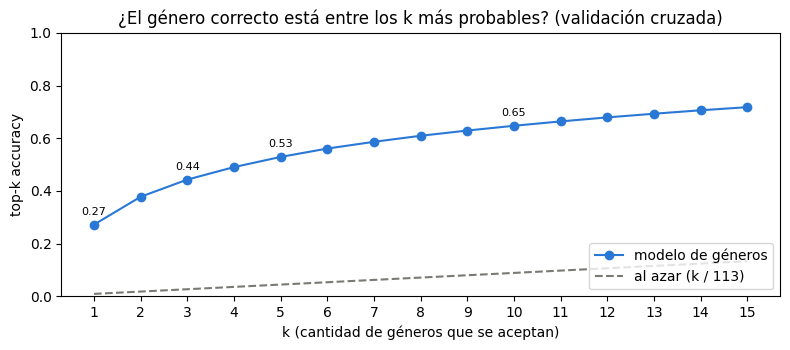

,top-k accuracy (CV),errores del top-1 recuperados
k,,
1,0.272,0.000
2,0.378,0.145
3,0.443,0.235
5,0.529,0.353
10,0.647,0.515


In [45]:
ks_curva = list(range(1, 16))
top_generos_cv = pd.Series({k: top_k_accuracy_score(y_train, proba_genero_oof.values, k=k, labels=proba_genero_oof.columns)
                            for k in ks_curva}, name="top-k accuracy (CV)")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ks_curva, top_generos_cv, marker="o", color=AZUL, label="modelo de géneros")
ax.plot(ks_curva, [k / 113 for k in ks_curva], color=GRIS, ls="--", label="al azar (k / 113)")
for k in (1, 3, 5, 10):
    ax.annotate(f"{top_generos_cv[k]:.2f}", (k, top_generos_cv[k]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set_xlabel("k (cantidad de géneros que se aceptan)"); ax.set_ylabel("top-k accuracy"); ax.set_ylim(0, 1)
ax.set_xticks(ks_curva); ax.legend(loc="lower right")
ax.set_title("¿El género correcto está entre los k más probables? (validación cruzada)")
plt.tight_layout()
plt.show()

# de las canciones que el top-1 falla, ¿cuántas se recuperan en el 2.º, 3.º o 5.º intento?
fallos_top1 = 1 - top_generos_cv[1]
pd.DataFrame({"top-k accuracy (CV)": top_generos_cv[[1, 2, 3, 5, 10]],
              "errores del top-1 recuperados": ((top_generos_cv[[1, 2, 3, 5, 10]] - top_generos_cv[1]) / fallos_top1)}
             ).rename_axis("k").round(3)

In [46]:
# lo mismo para las familias: top-1 y top-2, directo y jerárquico (top-2 no existe con 2 clases: siempre es 1)
cols = ["Clases", "Accuracy", "Top-2", "Top-3", "Kappa"]
tabla_top_familias = tabla_familias[cols].copy()
tabla_top_familias = tabla_top_familias.rename(columns={"Accuracy": "Top-1"})

# «no acertó la familia, pero estaba entre los 3 géneros más probables»: familia real ∈ familias de los top-3 géneros
top3_generos = np.argsort(-proba_genero_oof.values, axis=1)[:, :3]
columnas_genero = proba_genero_oof.columns.to_numpy()
fila_extra = {}
for nombre, mapa in AGRUPAMIENTOS.items():
    familias_top3 = mapa.reindex(columnas_genero).to_numpy()[top3_generos]
    real = y_train.map(mapa).to_numpy()[:, None]
    fila_extra[nombre] = (familias_top3 == real).any(axis=1).mean()
tabla_top_familias["Familia real entre los top-3 géneros"] = pd.Series(fila_extra).reindex(tabla_top_familias.index, level=0)
tabla_top_familias.round(3)

Clases  Top-1  Top-2  Top-3  Kappa  Familia real entre los top-3 géneros
Objetivo                   Modo                                                                                                  
Géneros (113)              directo                          113  0.272  0.378  0.443  0.264                                   NaN
k-means k=2 (silhouette)   directo                            2  0.887    NaN    NaN  0.627                                 0.948
                           jerárquico (géneros sumados)       2  0.887    NaN    NaN  0.597                                 0.948
k-means k=3                directo                            3  0.788  0.968    NaN  0.620                                 0.897
                           jerárquico (géneros sumados)       3  0.788  0.966    NaN  0.608                                 0.897
k-means k=10 (con nombres) directo                           10  0.542  0.748  0.864  0.471                                 0.733
                           jerárquico (géneros sumados)      10  0.546  0.747  0.867  0.469                                 0.733
k-means k=20               directo                           20  0.442  0.614  0.723  0.404                                 0.634
                           jerárquico (géneros sumados)      20  0.443  0.620  0.729  0.399                                 0.634
Manual 20                  directo                           20  0.412  0.552  0.644  0.358                                 0.596
                           jerárquico (géneros sumados)      20  0.416  0.557  0.649  0.347                                 0.596

**Lectura.** Medición preliminar, hecha fuera del notebook con un solo fold de entrenamiento como validación (el test no se tocó); ✏️ reemplazar con los números de CV de esta celda:

| Objetivo | Piso (accuracy) | Top-1 | Top-2 | Top-3 | κ | Familia real entre los top-3 géneros |
|---|---|---|---|---|---|---|
| 113 géneros | ~0,01 | 0,27 | 0,38 | 0,44 | — | — |
| k = 2 | 0,80 | 0,89 | — | — | 0,63 | 0,94 |
| k = 3 | 0,56 | 0,79 | 0,96 | — | 0,63 | 0,90 |
| **k = 10 (con nombres)** | 0,25 | **0,56** | **0,78** | **0,90** | 0,47 | 0,76 |

Además, top-5 de géneros = 0,53 y top-10 = 0,65. Cómo leerlo:

- **¿Está cerca?** Sí, bastante más de lo que dice el top-1. El modelo de géneros acierta el género exacto en el 27 % de los casos, pero el correcto está entre las tres primeras respuestas en el 44 %: **casi un cuarto de los errores del top-1 se recupera en el segundo o tercer intento**. Con k = 10, la familia correcta es la primera respuesta en el 56 % y está entre las dos primeras en el **78 %**.
- **k = 2 y 3 parecen mejores, pero no lo son.** El 0,89 de k = 2 está a nueve puntos de un piso de 0,80, y el top-2 de k = 3 (0,96) es casi gratis con tres clases. El κ, que descuenta el azar, es de ~0,63 en los dos.
- **k = 10 captura estructura real.** Con 10 familias sorteadas de la misma forma, el κ cae a 0,25 (top-1 0,41, top-3 0,75): las familias de k-means se predicen casi el doble de bien que unas arbitrarias.
- **No hace falta un modelo nuevo.** Directo y jerárquico dan lo mismo en los tres k (0,561 contra 0,560 de top-1 con k = 10). El modelo de 113 géneros ya contiene la información de la familia: alcanza con sumar sus probabilidades.

Para la app esto sugiere mostrar **la familia más probable (k = 10) y los tres géneros más probables**: con un solo modelo, la respuesta «útil» acierta mucho más seguido que el top-1.

## Parte 13 — Test final de las familias

Nada se elige acá: se informan **todas** las variantes definidas por CV, cada una medida **una vez**. Cada modelo de familias se entrena con todo el entrenamiento (el mismo pipeline congelado) y la versión jerárquica sale de las probabilidades del modelo de géneros que ya se midió en la Parte 8.

In [47]:
filas_test = [{"Objetivo": "Géneros (113)", "Modo": "directo", "Clases": 113,
               "F1 macro": f1_test, "Accuracy (top-1)": accuracy_test, "Top-2": top_k_accuracy_score(y_test, proba_test_genero.values, k=2, labels=modelo_final.classes_),
               "Top-3": top_test[3], "Kappa": cohen_kappa_score(y_test, y_pred)}]

def fila_test(objetivo_test, proba, nombre, modo):
    pred = proba.idxmax(axis=1)
    n = proba.shape[1]
    return {"Objetivo": nombre, "Modo": modo, "Clases": n,
            "F1 macro": f1_score(objetivo_test, pred, average="macro"), "Accuracy (top-1)": accuracy_score(objetivo_test, pred),
            "Top-2": top_k_accuracy_score(objetivo_test, proba.values, k=2, labels=proba.columns) if n > 2 else np.nan,
            "Top-3": top_k_accuracy_score(objetivo_test, proba.values, k=3, labels=proba.columns) if n > 3 else np.nan,
            "Kappa": cohen_kappa_score(objetivo_test, pred)}

MODELOS_FAMILIA = {}
for nombre, mapa in AGRUPAMIENTOS.items():
    print("Entrenando y midiendo:", nombre)
    MODELOS_FAMILIA[nombre] = clone(modelo_final).fit(X_sel, y_train.map(mapa))
    proba = pd.DataFrame(MODELOS_FAMILIA[nombre].predict_proba(X_test_final), columns=MODELOS_FAMILIA[nombre].classes_, index=X_test.index)
    objetivo_test = y_test.map(mapa)
    filas_test.append(fila_test(objetivo_test, proba, nombre, "directo"))
    filas_test.append(fila_test(objetivo_test, agregar_a_familias(proba_test_genero, mapa), nombre, "jerárquico (géneros sumados)"))

tabla_test_familias = pd.DataFrame(filas_test).set_index(["Objetivo", "Modo"])
tabla_test_familias.round(4)

Entrenando y midiendo: k-means k=2 (silhouette)
Entrenando y midiendo: k-means k=3
Entrenando y midiendo: k-means k=10 (con nombres)
Entrenando y midiendo: k-means k=20
Entrenando y midiendo: Manual 20


Clases  F1 macro  Accuracy (top-1)   Top-2   Top-3   Kappa
Objetivo                   Modo                                                                                    
Géneros (113)              directo                          113    0.2407            0.2815  0.3897  0.4540  0.2743
k-means k=2 (silhouette)   directo                            2    0.8175            0.8895     NaN     NaN  0.6357
                           jerárquico (géneros sumados)       2    0.8022            0.8884     NaN     NaN  0.6075
k-means k=3                directo                            3    0.7595            0.7901  0.9669     NaN  0.6218
                           jerárquico (géneros sumados)       3    0.7460            0.7885  0.9674     NaN  0.6067
k-means k=10 (con nombres) directo                           10    0.5909            0.5518  0.7494  0.8668  0.4817
                           jerárquico (géneros sumados)      10    0.5908            0.5548  0.7553  0.8711  0.4799
k-means k=20               directo                           20    0.4903            0.4492  0.6178  0.7243  0.4116
                           jerárquico (géneros sumados)      20    0.4880            0.4495  0.6232  0.7334  0.4063
Manual 20                  directo                           20    0.3454            0.4214  0.5627  0.6535  0.3693
                           jerárquico (géneros sumados)      20    0.3208            0.4184  0.5648  0.6570  0.3522

**Lectura.** ✏️ Estos números deben parecerse a los de CV de la Parte 11 (si no, algo se eligió mal). Se informan todos; la decisión de qué objetivo usar en la Entrega 4 se toma con la tabla de CV, no con esta.

## Parte 14 — Conclusión y exportación

### Síntesis para exponer (✏️ completar con los números finales)

- **Objetivo y validación:** 113 géneros, F1 macro, `StratifiedGroupKFold` de 5 folds agrupando audio idéntico, test externo mirado una vez.
- **Techo del problema, medido antes de modelar:** 1.020 filas con audio idéntico y géneros distintos en Plata, y 18 % de `track_id` multi-género en la fuente; subgéneros con perfiles casi idénticos (Parte 2).
- **Modelo:** Random Forest, elegido por CV con barra de error frente a cinco familias; F1 macro CV ✏️, test ✏️; top-3 ✏️.
- **Familias:** agrupar **canciones** es circular (10.2); agrupar **géneros** por perfil da un degradé (silhouette 0,34 con k = 2, ~0,2 para k ≥ 3). k = 10 con nombres es la granularidad más útil: κ ≈ 0,47 contra 0,25 de familias al azar, top-2 de familia ≈ 0,78 (preliminar).
- **Top-k:** el género exacto se acierta ~27 % de las veces, pero el correcto está entre los tres primeros ~44 % (preliminar); el modelo «está cerca» mucho más seguido de lo que dice el top-1.
- **Propuesta para la Entrega 4:** ✏️ según la Parte 11. Con lo medido hasta ahora: **un solo modelo de géneros** que muestre la familia de k = 10 (sumando probabilidades) y los tres géneros más probables.

Se guarda el **pipeline de géneros entrenado con el preprocesamiento incluido** (la app debe aportar exactamente `FEATURES_ELEGIDAS`), sus metadatos, y los mapas de familias con sus tablas de comparación, para que la Entrega 4 pueda congelar el objetivo antes de entrenar. No se reentrena con el test.

In [48]:
SALIDA_MODELO = "genreml_pipeline_entrega3.joblib"
joblib.dump(modelo_final, SALIDA_MODELO, compress=3)

metadata = {
    "proyecto": "GenreML", "objetivo": OBJETIVO, "familia": familia_elegida,
    "features": FEATURES_ELEGIDAS, "contrastes": bool(USAR_CONTRASTES),
    "numericas": [c for c in FEATURES_ELEGIDAS if c in NUMERICAS],
    "categoricas": [c for c in FEATURES_ELEGIDAS if c in CATEGORICAS],
    "hiperparametros": {k: (v if v is None or isinstance(v, (int, float, str)) else str(v)) for k, v in busqueda.best_params_.items()},
    "clases": [str(c) for c in modelo_final.classes_],
    "metrica_primaria": METRICA,
    "f1_macro_cv": float(busqueda.best_score_), "f1_macro_test": float(f1_test), "accuracy_test": float(accuracy_test),
    "top3_test": float(top_test[3]), "top5_test": float(top_test[5]),
    "semilla": SEMILLA, "sklearn_version": sklearn.__version__,
    "tratamiento_tempo": "0 imputado con mediana dentro del pipeline",
}
with open("genreml_metadata_entrega3.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

mapas = {nombre: {g: str(f) for g, f in mapa.sort_index().items()} for nombre, mapa in AGRUPAMIENTOS.items()}
with open("genreml_mapas_familias.json", "w", encoding="utf-8") as f:
    json.dump({"nota": "perfiles calculados sólo con el entrenamiento; k-means sobre los 113 perfiles escalados",
               "k_silhouette": int(K_SIL), "mapas": mapas}, f, ensure_ascii=False, indent=2)

tabla_familias.to_csv("genreml_familias_cv.csv", encoding="utf-8-sig")
tabla_test_familias.to_csv("genreml_familias_test.csv", encoding="utf-8-sig")
pd.concat({f"k={k}": describir(MAPAS_KMEANS[k]) for k in K_DESCRIPTOS}).to_csv("genreml_catalogo_kmeans.csv", encoding="utf-8-sig")

pd.Series({archivo: Path(archivo).exists() for archivo in
           [SALIDA_MODELO, "genreml_metadata_entrega3.json", "genreml_mapas_familias.json",
            "genreml_familias_cv.csv", "genreml_familias_test.csv", "genreml_catalogo_kmeans.csv"]}, name="guardado")

,guardado
genreml_pipeline_entrega3.joblib,True
genreml_metadata_entrega3.json,True
genreml_mapas_familias.json,True
genreml_familias_cv.csv,True
genreml_familias_test.csv,True
genreml_catalogo_kmeans.csv,True


## Cierre

El notebook deja un modelo de géneros elegido y medido con el método de la unidad, y una respuesta medida a la pregunta de las familias, en vez de una taxonomía elegida a mano. Queda abierto para la Entrega 4 congelar el objetivo (géneros con top-k, o familias) **antes** de entrenar el modelo de la app, y contrastar con música de otra fuente si se quiere afirmar generalización fuera de esta colección.